# From Supply–Demand Imbalance to Fair Curtailment
### Multi-source reconciliation, regime diagnosis, and fairness-constrained curtailment allocation


| Layer | Quantity | Column(s) |
|---|---|---|
| A — reported | divisional load shedding $L^{rep}_{d,t}$ | `*_load` |
| B — divisional imbalance | $G_{d,t}=D_{d,t}-S_{d,t}$ | `*_demand`, `*_supply` |
| C — national operational shortfall | $G^{peak}_t = D^{eve}_t - G^{eve}_t$ | evening-peak demand / generation |
| D — upstream constraints | Gas/LF, coal, Kaptai hydro, maintenance | limitation columns |

The notebook (1) reconciles these layers, (2) quantifies where they diverge, (3) identifies regimes (calendar + data-driven change points), (4) measures **when upstream constraints convert into consumer-level shortfall**, (5) models divisional **relative curtailment burden** $B_{d,t}=G_{d,t}/D_{d,t}$ with a panel regression and a nonlinear benchmark under rolling-origin validation, and (6) compares BPDB's observed allocation with proportional, min-max LP and temporal-fairness MILP allocations.



## Setup, Config, and Environment



In [39]:

import importlib, subprocess, sys
for pkg in ["lightgbm", "shap", "xgboost", "statsmodels"]:
    try:
        importlib.import_module(pkg)
    except ImportError:
        print(f"Installing {pkg}...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

# --- standard imports ---
import os, json, time, warnings, math
from dataclasses import dataclass, field
from pathlib import Path
from typing import Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy import sparse
from scipy.optimize import linprog, milp, LinearConstraint, Bounds

warnings.filterwarnings("ignore")
mpl.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "font.size": 10})

SEED = 20250101
np.random.seed(SEED)

In [40]:

@dataclass
class Config:
    # Data
    DATA_PATH: str = "/kaggle/input/datasets/mdlimonbinhossain/electricity-dataset/version 5.xlsx"
    LOCAL_FALLBACK: str = "/mnt/user-data/uploads/version_5.xlsx"

    # Runtime mode
    MODE: str = "FAST"            # "FAST" or "FULL"
    N_BOOTSTRAP_FAST: int = 200
    N_BOOTSTRAP_FULL: int = 2000
    BLOCK_LEN_DAYS: int = 14      # moving-block bootstrap block length (daily autocorrelation)

    # External (calendar) regime cutoffs (inclusive lower, exclusive upper)
    COVID_START: str    = "2019-11-21"
    COVID_END: str      = "2022-01-01"
    CRISIS_START: str   = "2022-01-01"
    CRISIS_END: str     = "2024-01-01"
    RECOVERY_START: str = "2024-01-01"
    RECOVERY_END: str   = "2025-01-01"

    # 9 divisions in the dataset
    DIVISIONS: tuple = (
        "Dhaka", "Chattogram", "Rajshahi", "Khulna", "Rangpur",
        "Mymensingh", "Sylhet", "Barishal", "Cumilla"
    )

    # Reconciliation / discrepancy classification
    CONSISTENCY_TOL_MW: float = 1.0      # |E| <= max(tol_MW, tol_frac * demand) -> consistent
    CONSISTENCY_TOL_FRAC: float = 0.005
    HIGH_DEMAND_Q: float = 0.75          # within-year quantile defining "high-demand" days

    # Data-driven regimes (binary segmentation on monthly z-scored system variables)
    CP_N_BREAKS: int = 3
    CP_MIN_SEG_MONTHS: int = 4

    # Feature engineering (lags are calendar-day lags; missing dates -> NaN)
    LAGS: tuple = (1, 3, 7)
    ROLL_WINDOWS: tuple = (3, 7)
    LAGGED_DRIVERS: tuple = ("gas", "maint", "nat_demand")   # upstream / demand stress
    LAGGED_STRESS: tuple = ("nat_gap",)                     # operational shortfall (early-warning only)

    # Validation & models
    ROLLING_ORIGINS: tuple = (2022, 2023, 2024)   # train on years < origin, test on origin
    MODELS: tuple = ("Persistence", "PanelRidge", "LightGBM", "LightGBM-L1", "Hurdle", "XGBoost")
    RIDGE_ALPHA: float = 100.0                    # chosen on the inner validation year (Section 13)
    # Small, regularised trees: ~560 shortage days do not support deep trees
    LGBM_PARAMS: dict = field(default_factory=lambda: dict(
        n_estimators=3000, learning_rate=0.02, num_leaves=7, min_data_in_leaf=100,
        feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1, lambda_l2=1.0,
        verbose=-1, random_state=SEED
    ))
    XGB_PARAMS: dict = field(default_factory=lambda: dict(
        n_estimators=3000, learning_rate=0.02, max_depth=3, min_child_weight=20,
        subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
        random_state=SEED, verbosity=0, tree_method="hist"
    ))
    EARLY_STOPPING_ROUNDS: int = 100   # early stopping on the last training year (never the test year)
    MIN_ROUNDS: int = 50
    FALLBACK_ROUNDS: int = 300         # used when the inner year has no usable variation
    RUN_QUARTERLY: bool = True         # quarterly expanding-window robustness check (Section 8c)
    QUARTERLY_START: str = "2022-04-01"
    RUN_SECTION_13: bool = True        # tuning & sensitivity section (adds several minutes)

    # Allocation (OR) layer
    ALLOC_YEARS_FAST: tuple = (2024,)
    ALLOC_YEARS_FULL: tuple = (2022, 2023, 2024)
    CAPACITY_WINDOW_DAYS: int = 30       # demonstrated delivery capacity = max supply in trailing window
    MILP_HORIZON_DAYS: int = 7           # rolling-horizon window (committed, non-overlapping)
    MILP_MIN_ACTIVE_FRAC: float = 0.01   # if a division is curtailed, at least 1% of its demand (feeder-block proxy)
    MILP_MAX_CONSEC_DAYS: int = 3        # rotation: at most K consecutive curtailment days (soft)
    MILP_W_CUM: float = 1.0              # weight: max cumulative burden rate (pp)
    MILP_W_RANGE: float = 1.0            # weight: range of cumulative burden rates (pp)
    MILP_W_DAY: float = 1.0              # weight: mean daily max burden (pp)
    MILP_W_OVER: float = 1.0             # weight: over-curtailment (% of window requirement)
    MILP_W_ROT: float = 0.5              # weight per rotation-violation day
    MILP_TIME_LIMIT_S: float = 20.0
    MILP_GAP: float = 0.01
    FRONTIER_K: tuple = (1, 2, 3, 5, None)   # None = no rotation constraint
    ATKINSON_EPS: float = 0.5

    # Output
    OUT_DIR: str = "/kaggle/working"
    LOCAL_OUT_DIR: str = "/tmp/dlsam_out"

    @property
    def n_bootstrap(self) -> int:
        return self.N_BOOTSTRAP_FAST if self.MODE == "FAST" else self.N_BOOTSTRAP_FULL

    @property
    def alloc_years(self) -> tuple:
        return self.ALLOC_YEARS_FAST if self.MODE == "FAST" else self.ALLOC_YEARS_FULL

    @property
    def out_dir(self) -> Path:
        p = Path(self.OUT_DIR)
        if not p.parent.exists():         # not on Kaggle → use local fallback
            p = Path(self.LOCAL_OUT_DIR)
        p.mkdir(parents=True, exist_ok=True)
        return p

CFG = Config()
print(f"MODE={CFG.MODE}  N_BOOTSTRAP={CFG.n_bootstrap}  SEED={SEED}  ALLOC_YEARS={CFG.alloc_years}")
print(f"OUT_DIR={CFG.out_dir}")

MODE=FAST  N_BOOTSTRAP=200  SEED=20250101  ALLOC_YEARS=(2024,)
OUT_DIR=/kaggle/working


In [41]:

import platform
env = {
    "python":  sys.version.split()[0],
    "platform": platform.platform(),
    "numpy":    np.__version__,
    "pandas":   pd.__version__,
}
for m in ("scipy", "sklearn", "statsmodels", "lightgbm", "xgboost", "shap"):
    try:
        env[m] = importlib.import_module(m).__version__
    except Exception:
        env[m] = "not installed"

for k, v in env.items():
    print(f"  {k:12s} {v}")

  python       3.12.13
  platform     Linux-6.12.90+-x86_64-with-glibc2.35
  numpy        2.0.2
  pandas       2.3.3
  scipy        1.16.3
  sklearn      1.6.1
  statsmodels  0.14.6
  lightgbm     4.6.0
  xgboost      3.2.0
  shap         0.51.0


## Data Loading, Structural Validation & Data-Quality Report


In [42]:
def load_dataset(cfg: Config) -> pd.DataFrame:
    # Load version_5.xlsx from Kaggle input or local fallback.
    for path in (cfg.DATA_PATH, cfg.LOCAL_FALLBACK):
        if os.path.exists(path):
            print(f"Loading: {path}")
            df = pd.read_excel(path)
            break
    else:
        raise FileNotFoundError(
            f"Dataset not found. Tried:\n  {cfg.DATA_PATH}\n  {cfg.LOCAL_FALLBACK}\n"
            "Attach the Kaggle Dataset or set Config.DATA_PATH."
        )

    df["Date"] = pd.to_datetime(df["Date"])
    df = df.sort_values("Date").reset_index(drop=True)
    return df

df = load_dataset(CFG)

# --- structural validation ---
required = ["Date", "Gas/LF limitation", "Coal supply Limitation",
            "Low water level in Kaptai lake", "Plants under shut down/ maintenance",
            "Max. Demand at eve. peak (Generation end)",
            "Evening-peak Generation (Generation end)",
            "Maximum Temperature in Dhaka was", "Holiday_cat"]
for c in required:
    assert c in df.columns, f"Missing required column: {c}"
for d in CFG.DIVISIONS:
    for suf in ("_demand", "_supply", "_load"):
        assert f"{d}{suf}" in df.columns, f"Missing column: {d}{suf}"
assert not df["Date"].duplicated().any(), "Duplicated dates"

DIVS        = list(CFG.DIVISIONS)
LOAD_COLS   = [f"{d}_load"   for d in DIVS]
DEMAND_COLS = [f"{d}_demand" for d in DIVS]
SUPPLY_COLS = [f"{d}_supply" for d in DIVS]
FULL_RANGE  = pd.date_range(df.Date.min(), df.Date.max(), freq="D")

print(f"Rows: {len(df):,}   Columns: {df.shape[1]}   Date range: {df.Date.min().date()} → {df.Date.max().date()}")
print(f"Divisions validated: {len(DIVS)}")

Loading: /kaggle/input/datasets/mdlimonbinhossain/electricity-dataset/version 5.xlsx
Rows: 1,850   Columns: 45   Date range: 2019-11-21 → 2024-12-30
Divisions validated: 9


In [43]:

missing_days = FULL_RANGE.difference(df["Date"])
gap_raw   = df[DEMAND_COLS].values - df[SUPPLY_COLS].values
identity  = gap_raw - df[LOAD_COLS].values                    # E = (D - S) - L_rep
dup_mask  = ((df["Rajshahi_demand"] == df["Khulna_demand"]) & (df["Rajshahi_supply"] == df["Khulna_supply"])
             & (df["Barishal_demand"] == df["Rangpur_demand"]) & (df["Barishal_supply"] == df["Rangpur_supply"]))
df["dq_duplicated_division_series"] = dup_mask.astype(int)

DQ = {
    "missing_calendar_days": int(len(missing_days)),
    "year_field_mismatch":   int((df["Year"] != df["Date"].dt.year).sum()),
    "month_field_mismatch":  int((df["Month"] != df["Date"].dt.month).sum()),
    "any_missing_values":    int(df.isna().sum().sum()),
    "division_days":         int(identity.size),
    "identity_violations":   int((identity != 0).sum()),
    "identity_violation_pct": round(100 * (identity != 0).mean(), 3),
    "negative_gap_division_days": int((gap_raw < 0).sum()),
    "duplicated_division_series_days": int(dup_mask.sum()),
}
print("Data-quality report")
for k, v in DQ.items():
    print(f"  {k:34s} {v}")
print(f"\nMissing dates: {[str(x.date()) for x in missing_days]}")
if dup_mask.any():
    print(f"Duplicated Rajshahi=Khulna & Barishal=Rangpur series: "
          f"{df.loc[dup_mask,'Date'].min().date()} → {df.loc[dup_mask,'Date'].max().date()} "
          "(likely data-entry duplication; flagged in `dq_duplicated_division_series`).")
print("\nIdentity violations per division (E = (D-S) - L_rep != 0):")
print(pd.Series((identity != 0).sum(axis=0), index=DIVS).to_string())

Data-quality report
  missing_calendar_days              17
  year_field_mismatch                0
  month_field_mismatch               0
  any_missing_values                 0
  division_days                      16650
  identity_violations                74
  identity_violation_pct             0.444
  negative_gap_division_days         11
  duplicated_division_series_days    112

Missing dates: ['2020-01-02', '2020-03-27', '2020-03-28', '2023-01-23', '2023-03-15', '2023-04-01', '2023-05-08', '2023-05-16', '2023-07-05', '2024-06-03', '2024-07-01', '2024-07-18', '2024-07-19', '2024-07-20', '2024-07-21', '2024-07-22', '2024-07-23']
Duplicated Rajshahi=Khulna & Barishal=Rangpur series: 2019-11-21 → 2020-03-14 (likely data-entry duplication; flagged in `dq_duplicated_division_series`).

Identity violations per division (E = (D-S) - L_rep != 0):
Dhaka          5
Chattogram     4
Rajshahi       5
Khulna         4
Rangpur        5
Mymensingh    20
Sylhet        17
Barishal       3
Cumilla   

##  Multi-Source Reconciliation

We place the four layers side by side, per day and per year:

* $L^{rep}_t=\sum_d L^{rep}_{d,t}$ (reported shedding)
* $G^{div}_t=\sum_d \max(D_{d,t}-S_{d,t},0)$ (divisional imbalance) and burden $B_{d,t}=100\,G_{d,t}/D_{d,t}$ (%)
* $G^{peak}_t = D^{eve}_t - G^{eve}_t$ (national operational shortfall, generation end)
* $C_t = Gas_t+Coal_t+Hydro_t$ and $M_t$ = plants under shutdown/maintenance (upstream constraints, kept **separate** — they can overlap, so they are not added)



In [44]:
GAP_COLS    = [f"{d}_gap"    for d in DIVS]
BURDEN_COLS = [f"{d}_burden" for d in DIVS]
DISC_COLS   = [f"{d}_disc"   for d in DIVS]

for d in DIVS:
    df[f"{d}_gap_raw"] = df[f"{d}_demand"] - df[f"{d}_supply"]
    df[f"{d}_gap"]     = df[f"{d}_gap_raw"].clip(lower=0)
    df[f"{d}_burden"]  = 100 * df[f"{d}_gap"] / df[f"{d}_demand"]
    df[f"{d}_disc"]    = df[f"{d}_gap_raw"] - df[f"{d}_load"]          # E_{d,t}

df["total_reported_shedding"] = df[LOAD_COLS].sum(axis=1)
df["total_div_gap"]           = df[GAP_COLS].sum(axis=1)
df["total_div_demand"]        = df[DEMAND_COLS].sum(axis=1)
df["system_burden"]           = 100 * df["total_div_gap"] / df["total_div_demand"]
df["national_demand"]         = df["Max. Demand at eve. peak (Generation end)"]
df["national_peak_gap"]       = df["national_demand"] - df["Evening-peak Generation (Generation end)"]
df["upstream_constraints"]    = (df["Gas/LF limitation"] + df["Coal supply Limitation"]
                                 + df["Low water level in Kaptai lake"])
df["maintenance"]             = df["Plants under shut down/ maintenance"]
df["nat_minus_div_gap"]       = df["national_peak_gap"].clip(lower=0) - df["total_div_gap"]

def assign_regime(date, cfg: Config):
    if date < pd.Timestamp(cfg.CRISIS_START):   return "covid"
    if date < pd.Timestamp(cfg.RECOVERY_START): return "crisis"
    return "recovery"

df["regime"] = df["Date"].apply(lambda d: assign_regime(d, CFG))
df["year"]   = df["Date"].dt.year
df["month"]  = df["Date"].dt.month
df["dow"]    = df["Date"].dt.dayofweek
df["holiday_group"] = np.where(df["Holiday_cat"] > 0, "holiday", "working")
q_hi = df.groupby("year")["national_demand"].transform(lambda s: s.quantile(CFG.HIGH_DEMAND_Q))
df["demand_group"]  = np.where(df["national_demand"] >= q_hi, "high-demand", "normal-demand")

LAYERS = {
    "total_reported_shedding": "Reported shedding (Σ L_rep)",
    "total_div_gap":           "Divisional imbalance (Σ max(D−S,0))",
    "national_peak_gap":       "National peak shortfall (D_eve − G_eve)",
    "upstream_constraints":    "Gas + coal + hydro limitation",
    "maintenance":             "Plants under shutdown/maintenance",
}
recon_overall = df[list(LAYERS)].mean().rename(index=LAYERS).round(1).to_frame("Mean MW/day")
recon_by_year = df.groupby("year")[list(LAYERS)].mean().rename(columns=LAYERS).round(1)
print("Layer means — whole sample:\n"); print(recon_overall.to_string())
print("\nLayer means by year (MW/day):\n"); print(recon_by_year.to_string())

ratio = df["upstream_constraints"].mean() / max(df["total_div_gap"].mean(), 1e-9)
print(f"\nGas+coal+hydro limitation is {ratio:.1f}x the observed divisional imbalance on average; "
      "they are not the same physical quantity.")
print("\nSpearman correlation between layers (daily):")
print(df[list(LAYERS)].rename(columns=LAYERS).corr(method="spearman").round(2).to_string())

Layer means — whole sample:

                                         Mean MW/day
Reported shedding (Σ L_rep)                    127.0
Divisional imbalance (Σ max(D−S,0))            127.5
National peak shortfall (D_eve − G_eve)        125.1
Gas + coal + hydro limitation                 2633.4
Plants under shutdown/maintenance             2189.5

Layer means by year (MW/day):

      Reported shedding (Σ L_rep)  Divisional imbalance (Σ max(D−S,0))  National peak shortfall (D_eve − G_eve)  Gas + coal + hydro limitation  Plants under shutdown/maintenance
year                                                                                                                                                                             
2019                          0.0                                  0.0                                     -1.3                         1322.7                              761.4
2020                          1.5                                  0.3                 

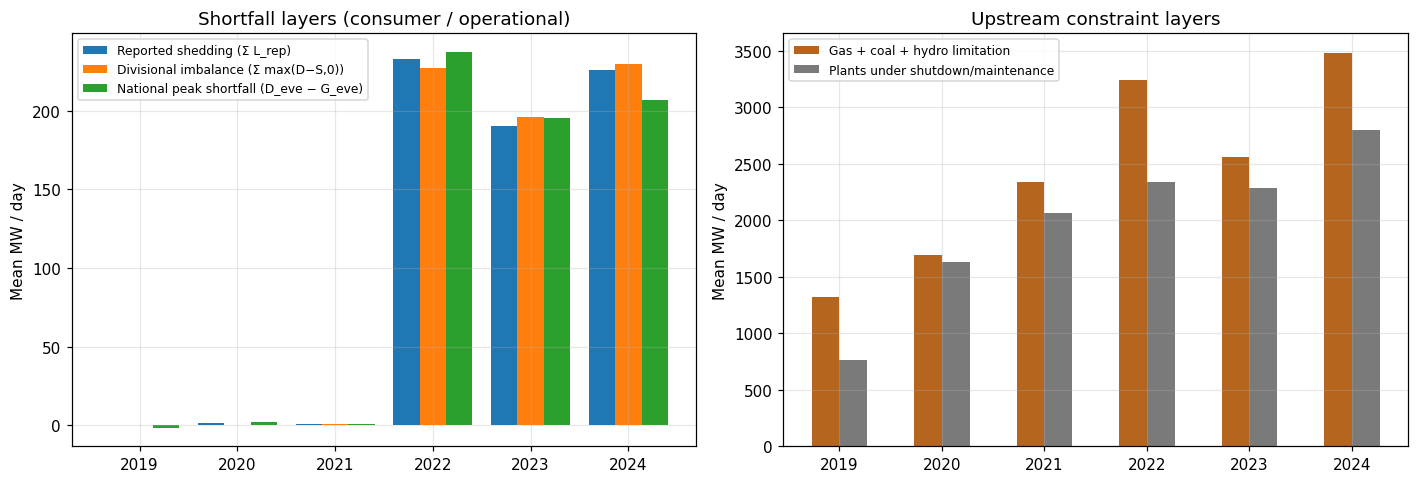

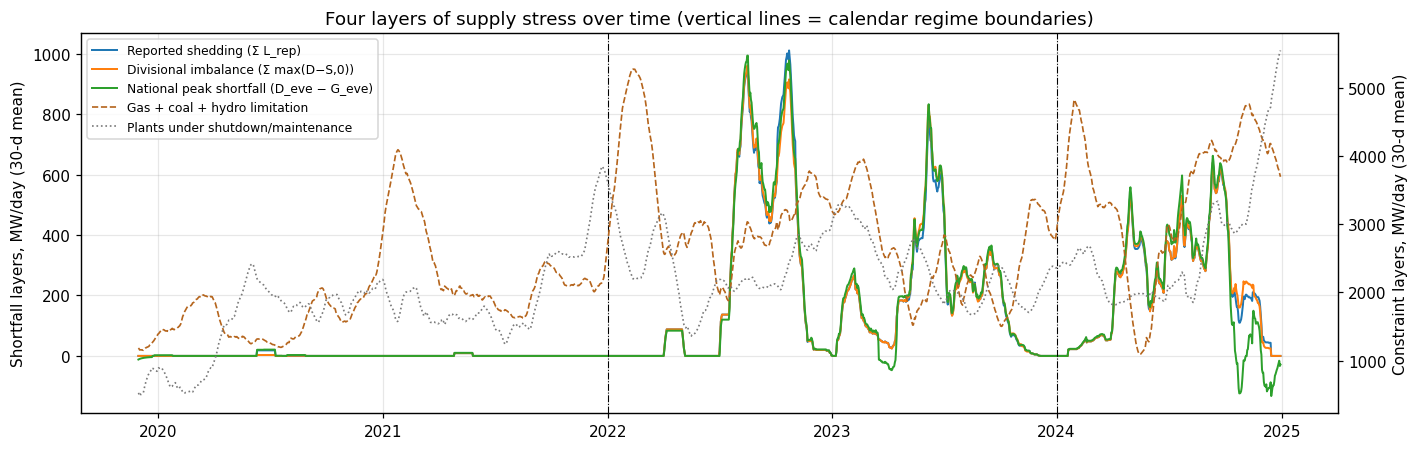

In [45]:

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
x = np.arange(len(recon_by_year)); w = 0.27
left  = ["total_reported_shedding", "total_div_gap", "national_peak_gap"]
right = ["upstream_constraints", "maintenance"]
for i, c in enumerate(left):
    axes[0].bar(x + (i - 1) * w, recon_by_year[LAYERS[c]], width=w, label=LAYERS[c])
for i, c in enumerate(right):
    axes[1].bar(x + (i - 0.5) * w, recon_by_year[LAYERS[c]], width=w, label=LAYERS[c],
                color=["#b5651d", "#7a7a7a"][i])
for ax, t in zip(axes, ["Shortfall layers (consumer / operational)", "Upstream constraint layers"]):
    ax.set_xticks(x); ax.set_xticklabels(recon_by_year.index)
    ax.set_ylabel("Mean MW / day"); ax.set_title(t); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(CFG.out_dir / "fig1_reconciliation_by_year.png", dpi=150)
plt.show()

# Figure 2: 30-day rolling means over time
roll = df.set_index("Date")[list(LAYERS)].reindex(FULL_RANGE).rolling(30, min_periods=10).mean()
fig, ax1 = plt.subplots(figsize=(13, 4.2))
for c in left:
    ax1.plot(roll.index, roll[c], label=LAYERS[c], lw=1.3)
ax1.set_ylabel("Shortfall layers, MW/day (30-d mean)")
ax2 = ax1.twinx()
ax2.plot(roll.index, roll["upstream_constraints"], color="#b5651d", ls="--", lw=1.1, label=LAYERS["upstream_constraints"])
ax2.plot(roll.index, roll["maintenance"], color="#7a7a7a", ls=":", lw=1.1, label=LAYERS["maintenance"])
ax2.set_ylabel("Constraint layers, MW/day (30-d mean)")
for b in (CFG.CRISIS_START, CFG.RECOVERY_START):
    ax1.axvline(pd.Timestamp(b), color="k", lw=0.7, ls="-.")
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, fontsize=8, loc="upper left"); ax1.grid(alpha=0.3)
ax1.set_title("Four layers of supply stress over time (vertical lines = calendar regime boundaries)")
plt.tight_layout()
plt.savefig(CFG.out_dir / "fig2_layers_timeseries.png", dpi=600)
plt.show()

## Measurement-Consistency Analysis

Neither source is treated as ground truth. Two discrepancies are measured:

1. **Divisional reporting discrepancy** $E_{d,t}=(D_{d,t}-S_{d,t})-L^{rep}_{d,t}$, classified as *consistent* ($|E|\le\max(1\text{ MW},0.5\%\,D)$), *under-reported* (imbalance > reported) or *over-reported*.
2. **National–divisional discrepancy** $E^{nat}_t=\max(G^{peak}_t,0)-G^{div}_t$ (generation-end vs. sub-station/divisional accounting; differences include losses, auxiliary use, timing of the peak).

Uncertainty uses a **moving-block bootstrap** (blocks of `BLOCK_LEN_DAYS` consecutive days resampled from the full timeline) so daily autocorrelation is preserved; group means are recomputed on each resample.

In [46]:
def block_bootstrap(frame: pd.DataFrame, stat_fn, cfg: Config, seed: int = SEED) -> pd.DataFrame:
    # Moving-block bootstrap: resample blocks of consecutive rows (days), recompute stat_fn -> pd.Series.
    rng = np.random.default_rng(seed)
    n, L = len(frame), cfg.BLOCK_LEN_DAYS
    k = int(np.ceil(n / L))
    point = stat_fn(frame)
    draws = []
    for _ in range(cfg.n_bootstrap):
        starts = rng.integers(0, n - L + 1, size=k)
        idx = (starts[:, None] + np.arange(L)).ravel()[:n]
        draws.append(stat_fn(frame.iloc[idx]))
    draws = pd.DataFrame(draws)
    return pd.DataFrame({"estimate": point,
                         "ci_low":  draws.quantile(0.025),
                         "ci_high": draws.quantile(0.975)})

def grouped_means(cols, groupers):
    # stat_fn factory: mean of each col within each level of each grouper -> flat Series.
    def fn(f):
        out = {}
        for c in cols:
            out[(c, "all", "all")] = f[c].mean()
            for g in groupers:
                for lvl, v in f.groupby(g)[c].mean().items():
                    out[(c, g, str(lvl))] = v
        return pd.Series(out)
    return fn

# ---- 1. divisional reporting discrepancy ----
tol = np.maximum(CFG.CONSISTENCY_TOL_MW, CFG.CONSISTENCY_TOL_FRAC * df[DEMAND_COLS].values)
E = df[DISC_COLS].values
cls = np.where(np.abs(E) <= tol, "consistent", np.where(E > 0, "under-reported", "over-reported"))
disc_table = pd.DataFrame({
    "Division": DIVS,
    "Consistent days": (cls == "consistent").sum(axis=0),
    "Under-reported days": (cls == "under-reported").sum(axis=0),
    "Over-reported days": (cls == "over-reported").sum(axis=0),
    "Mean E (MW)": E.mean(axis=0).round(2),
    "Mean |E| when inconsistent (MW)": [np.abs(E[cls[:, j] != "consistent", j]).mean()
                                        if (cls[:, j] != "consistent").any() else 0.0
                                        for j in range(len(DIVS))],
}).round(1)
share_consistent = 100 * (cls == "consistent").mean()
print(f"Division-days consistent with L_rep = D - S: {share_consistent:.2f}%\n")
print(disc_table.to_string(index=False))

incons = pd.DataFrame(cls != "consistent", columns=DIVS).assign(year=df["year"]).groupby("year").sum()
print("\nInconsistent division-days by year:"); print(incons.to_string())

print(f"\nInterpretation: the reported shedding column equals the divisional D − S accounting identity on "
      f"{share_consistent:.2f}% of division-days. The remaining {int((cls != 'consistent').sum())} division-days are "
      "sporadic, sometimes large, single-day deviations (consistent with data-entry errors) rather than a systematic "
      "bias. Layers A and B are therefore effectively one layer; the substantive divergence is between divisional "
      "imbalance, national peak shortfall and upstream constraints (analysed below).")

Division-days consistent with L_rep = D - S: 99.60%

  Division  Consistent days  Under-reported days  Over-reported days  Mean E (MW)  Mean |E| when inconsistent (MW)
     Dhaka             1847                    2                   1         -0.3                            910.0
Chattogram             1846                    3                   1          0.0                            222.0
  Rajshahi             1846                    2                   2         -0.1                            128.5
    Khulna             1846                    2                   2          0.1                            175.2
   Rangpur             1845                    3                   2         -0.0                             97.8
Mymensingh             1830                   15                   5          0.3                            159.2
    Sylhet             1834                    8                   8         -0.1                            104.6
  Barishal             1847

Block-bootstrap 95% CIs (moving blocks of 14 days, B=200):

                                               estimate  ci_low  ci_high
quantity          grouping      level                                   
nat_minus_div_gap all           all                4.85    0.63     8.66
                  year          2019               1.61    0.00     6.93
                                2020               1.66    0.00     5.22
                                2021               0.08    0.00     0.26
                                2022               9.85    1.73    21.28
                                2023               5.32    0.27     9.98
                                2024               7.77  -10.31    22.20
                  regime        covid              0.91    0.08     2.68
                                crisis             7.60    2.85    13.34
                                recovery           7.77  -10.31    22.20
                  holiday_group holiday            2.96   -1.29 

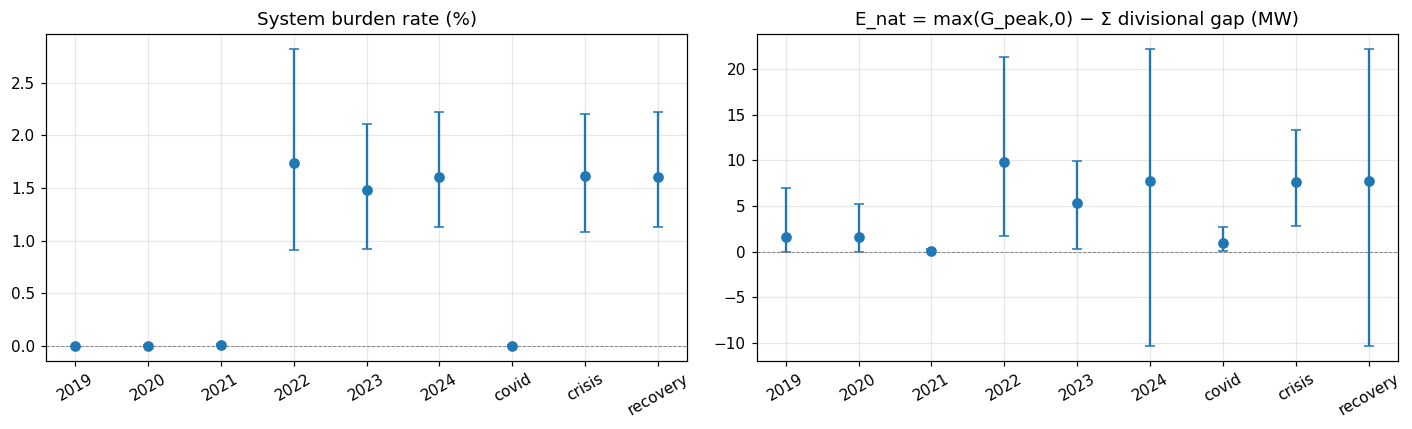

In [47]:
# ---- 2. national-divisional discrepancy and system burden, with block-bootstrap CIs ----
boot_cols = ["nat_minus_div_gap", "system_burden", "total_div_gap"]
boot_groups = ["year", "regime", "holiday_group", "demand_group"]
disc_ci = block_bootstrap(df[boot_cols + boot_groups], grouped_means(boot_cols, boot_groups), CFG)
disc_ci.index.names = ["quantity", "grouping", "level"]
disc_ci = disc_ci.round(2)
print("Block-bootstrap 95% CIs (moving blocks of "
      f"{CFG.BLOCK_LEN_DAYS} days, B={CFG.n_bootstrap}):\n")
print(disc_ci.to_string())

# Figure 3: CIs by year and regime
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, q, lab in zip(axes, ["system_burden", "nat_minus_div_gap"],
                      ["System burden rate (%)", "E_nat = max(G_peak,0) − Σ divisional gap (MW)"]):
    sub = disc_ci.loc[q].loc[["year", "regime"]].reset_index()
    xs = np.arange(len(sub))
    ax.errorbar(xs, sub["estimate"], yerr=[sub["estimate"] - sub["ci_low"], sub["ci_high"] - sub["estimate"]],
                fmt="o", capsize=3)
    ax.axhline(0, color="grey", lw=0.6, ls="--")
    ax.set_xticks(xs); ax.set_xticklabels(sub["level"], rotation=30)
    ax.set_title(lab); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(CFG.out_dir / "fig3_discrepancy_ci.png", dpi=600)
plt.show()

## Regime Identification (External vs Data-Driven)

**External regime**: the calendar split (COVID / fuel crisis / recovery) assigned.

**Data-driven regime**: binary segmentation (least-squares cost) on monthly means of z-scored
{Gas, Coal, Hydro, Maintenance, national demand, evening-peak generation, system burden}. We then ask whether the statistically detected states correspond to the calendar periods (cross-tab + adjusted Rand index). Change-point detection is used deliberately instead of HMMs/deep sequence models.

Detected change points (month start): ['2020-05-01', '2021-09-01', '2024-09-01']

Adjusted Rand index (calendar vs data-driven regimes): 0.422

Cross-tab (days):
cp_regime   S1   S2   S3   S4
regime                       
covid      159  488  122    0
crisis       0    0  724    0
recovery     0    0  236  121

Mean system variables by data-driven state:
              Gas   Coal  Hydro  Maintenance   Demand  Generation  Imbalance
cp_regime                                                                   
S1         1392.8   15.6  153.8        905.8   8991.1      8991.4        0.0
S2         1686.7  198.3  150.1       1797.3  10994.4     10992.3        0.0
S3         2698.5   95.9   98.5       2359.6  12282.6     12082.9        1.4
S4         4060.9    5.9   66.5       3938.1  12441.3     12323.2        1.5


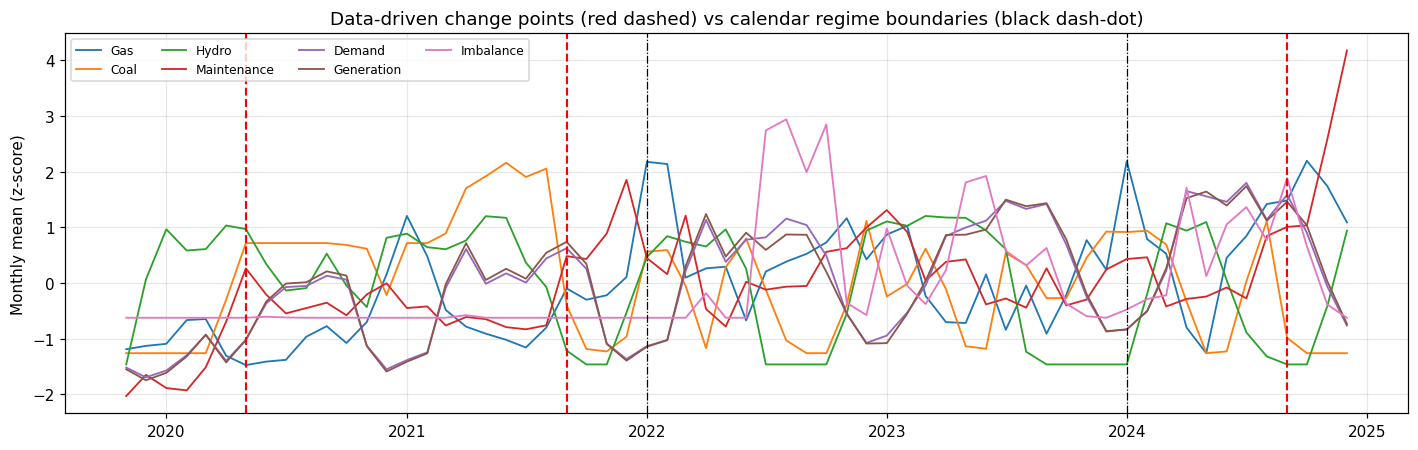

In [48]:
from sklearn.metrics import adjusted_rand_score

def binary_segmentation(X: np.ndarray, n_breaks: int, min_size: int) -> list:
    # Greedy binary segmentation with an L2 (within-segment sum of squares) cost.
    def cost(a, b):
        seg = X[a:b]
        return float(((seg - seg.mean(axis=0)) ** 2).sum())
    segments, breaks = [(0, len(X))], []
    for _ in range(n_breaks):
        best = None
        for (a, b) in segments:
            if b - a < 2 * min_size:
                continue
            base = cost(a, b)
            for t in range(a + min_size, b - min_size + 1):
                gain = base - cost(a, t) - cost(t, b)
                if best is None or gain > best[0]:
                    best = (gain, a, b, t)
        if best is None:
            break
        _, a, b, t = best
        segments.remove((a, b)); segments += [(a, t), (t, b)]
        breaks.append(t)
    return sorted(breaks)

CP_VARS = {"Gas/LF limitation": "Gas", "Coal supply Limitation": "Coal",
           "Low water level in Kaptai lake": "Hydro", "maintenance": "Maintenance",
           "national_demand": "Demand", "Evening-peak Generation (Generation end)": "Generation",
           "system_burden": "Imbalance"}
monthly = df.set_index("Date")[list(CP_VARS)].resample("MS").mean().rename(columns=CP_VARS)
monthly_z = (monthly - monthly.mean()) / monthly.std(ddof=0)
cp_idx = binary_segmentation(monthly_z.values, CFG.CP_N_BREAKS, CFG.CP_MIN_SEG_MONTHS)
cp_dates = [monthly_z.index[i] for i in cp_idx]
print("Detected change points (month start):", [str(d.date()) for d in cp_dates])

def assign_cp_regime(date):
    k = sum(date >= b for b in cp_dates)
    return f"S{k + 1}"
df["cp_regime"] = df["Date"].apply(assign_cp_regime)

ari = adjusted_rand_score(df["regime"], df["cp_regime"])
print(f"\nAdjusted Rand index (calendar vs data-driven regimes): {ari:.3f}")
print("\nCross-tab (days):")
print(pd.crosstab(df["regime"], df["cp_regime"]).to_string())
print("\nMean system variables by data-driven state:")
print(df.groupby("cp_regime")[list(CP_VARS)].mean().rename(columns=CP_VARS).round(1).to_string())

# Figure 4
fig, ax = plt.subplots(figsize=(13, 4.2))
for c in monthly_z.columns:
    ax.plot(monthly_z.index, monthly_z[c], lw=1.2, label=c)
for b in cp_dates:
    ax.axvline(b, color="red", lw=1.4, ls="--")
for b in (CFG.CRISIS_START, CFG.RECOVERY_START):
    ax.axvline(pd.Timestamp(b), color="k", lw=0.8, ls="-.")
ax.set_ylabel("Monthly mean (z-score)")
ax.set_title("Data-driven change points (red dashed) vs calendar regime boundaries (black dash-dot)")
ax.legend(ncol=4, fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(CFG.out_dir / "fig4_change_points.png", dpi=600)
plt.show()

## Constraint-to-Shortfall Conversion

$\text{fuel shortage} \neq \text{generation shortage} \neq \text{load shedding}$. We therefore measure the **conversion ratio**

$$\eta = \frac{\sum_t G^{div}_t}{\sum_t C_t}\qquad\text{and}\qquad \eta^{M} = \frac{\sum_t G^{div}_t}{\sum_t (C_t+M_t)}$$

(ratios of sums, which are robust to near-zero denominators), by month and by regime, and the probability of any consumer-level shortfall conditional on the constraint level. $C+M$ is only used as a *scale* for the ratio, not as a claim that the two are additive.

Conversion ratio (% of constraint MW that appears as divisional shortfall), block-bootstrap 95% CI:

                           estimate  ci_low  ci_high
ratio  grouping  level                              
eta_C  regime    covid         0.03    0.00     0.07
                 crisis        7.29    4.53    10.33
                 recovery      6.60    4.27    10.00
eta_CM regime    covid         0.01    0.00     0.03
                 crisis        4.06    2.54     5.55
                 recovery      3.65    2.41     5.50
eta_C  cp_regime S1            0.00    0.00     0.00
                 S2            0.04    0.00     0.10
                 S3            6.69    4.46     9.32
                 S4            5.19    1.41    10.04
eta_CM cp_regime S1            0.00    0.00     0.00
                 S2            0.02    0.00     0.06
                 S3            3.69    2.48     4.99
                 S4            2.66    0.70     5.63
eta_C  year      2019          0.00    0.00     0.0

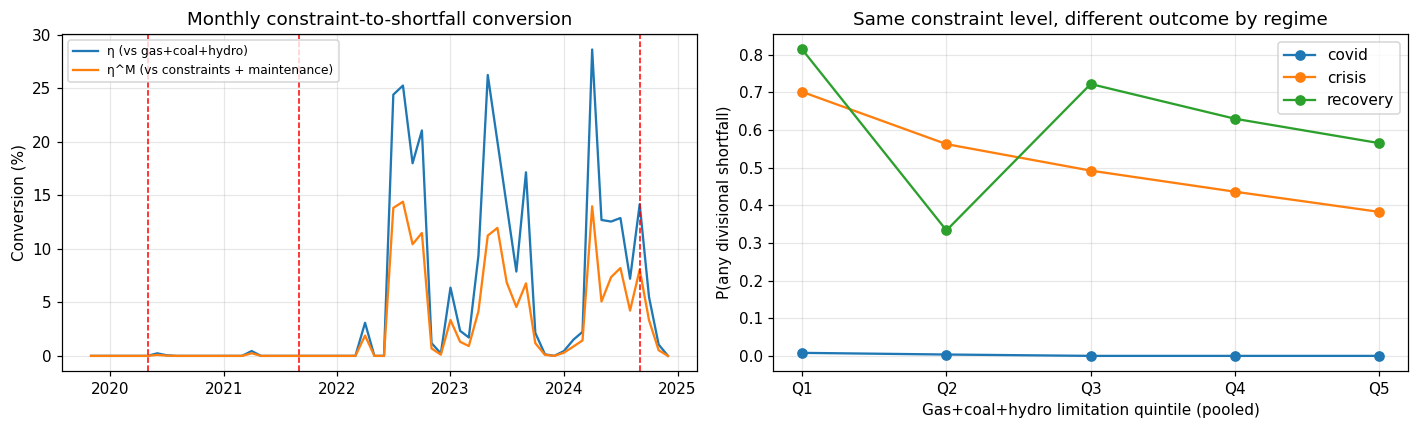

In [49]:
def eta_by(frame, by):
    g = frame.groupby(by)
    return pd.DataFrame({
        "eta_C":  g["total_div_gap"].sum() / g["upstream_constraints"].sum(),
        "eta_CM": g["total_div_gap"].sum() / (g["upstream_constraints"].sum() + g["maintenance"].sum()),
    })

conv_cols = ["total_div_gap", "upstream_constraints", "maintenance", "regime", "cp_regime", "year"]
def eta_stat(f):
    out = {}
    for by in ("regime", "cp_regime", "year"):
        e = eta_by(f, by)
        for lvl, v in e["eta_C"].items():  out[("eta_C", by, str(lvl))] = 100 * v
        for lvl, v in e["eta_CM"].items(): out[("eta_CM", by, str(lvl))] = 100 * v
    return pd.Series(out)
eta_ci = block_bootstrap(df[conv_cols], eta_stat, CFG).round(2)
eta_ci.index.names = ["ratio", "grouping", "level"]
print("Conversion ratio (% of constraint MW that appears as divisional shortfall), block-bootstrap 95% CI:\n")
print(eta_ci.to_string())

# P(any shortfall | constraint quintile) by regime (quintiles pooled over the full sample)
df["C_quintile"] = pd.qcut(df["upstream_constraints"], 5, labels=[f"Q{i}" for i in range(1, 6)])
p_short = (df.assign(any_short=df["total_div_gap"] > 0)
             .pivot_table(index="C_quintile", columns="regime", values="any_short", aggfunc="mean", observed=False))
c_edges = df.groupby("C_quintile", observed=False)["upstream_constraints"].agg(["min", "max"]).astype(int)
print("\nP(any divisional shortfall) by constraint quintile and regime:")
print(pd.concat([c_edges, p_short.round(3)], axis=1).to_string())

# Figure 5
monthly_eta = eta_by(df.set_index("Date"), pd.Grouper(freq="MS"))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(monthly_eta.index, 100 * monthly_eta["eta_C"], label="η (vs gas+coal+hydro)")
axes[0].plot(monthly_eta.index, 100 * monthly_eta["eta_CM"], label="η^M (vs constraints + maintenance)")
for b in cp_dates: axes[0].axvline(b, color="red", lw=1, ls="--")
axes[0].set_ylabel("Conversion (%)"); axes[0].set_title("Monthly constraint-to-shortfall conversion")
axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)
for r in p_short.columns:
    axes[1].plot(p_short.index.astype(str), p_short[r], marker="o", label=r)
axes[1].set_xlabel("Gas+coal+hydro limitation quintile (pooled)")
axes[1].set_ylabel("P(any divisional shortfall)")
axes[1].set_title("Same constraint level, different outcome by regime")
axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(CFG.out_dir / "fig5_conversion.png", dpi=600)
plt.show()

## Panel Construction & Feature Engineering

One division-day panel ($1{,}850\times9$ rows). Target: **relative curtailment burden** $B_{d,t}=100\,\max(D-S,0)/D$ (%).

| Block | Features | Diagnostic | Nowcast | Early warning |
|---|---|---|---|---|
| System (today) | gas, coal, hydro, maintenance, national demand, temperature | ✔ | ✔ | ✘ |
| Lagged drivers | $X_{t-1},X_{t-3},X_{t-7}$, $MA_3$, $MA_7$ (past-only) of gas, maintenance, demand | ✔ | ✔ | ✔ |
| Lagged stress | lags / past MAs of national peak shortfall | ✘ | ✘ | ✔ |
| Own history | burden$_{t-1}$, burden$_{t-7}$, past $MA_7$ | ✘ | ✔ | ✔ |
| Division | division id, demand share, demand vs past-7-day mean (lagged share for early warning) | ✔ | ✔ | ✔ |
| Calendar | holiday category, day of week, month | ✔ | ✔ | ✔ |

The *diagnostic* set is explanatory and deliberately excludes own burden history; the *nowcast* set adds it for the best same-day estimate; the *early-warning* set uses only information available by $t-1$. A richer set of own-history features (more lags, rolling max/std, days since last shortfall, run length) was tested and added almost nothing, so it is not included.

Lags are **calendar-day** lags (the 17 missing dates become NaN rather than silently shifting). Generation columns are excluded (leakage guard).

In [50]:
def cal_shift(s: pd.Series, k: int) -> pd.Series:
    return s.reindex(FULL_RANGE).shift(k).reindex(s.index)

def cal_past_mean(s: pd.Series, w: int) -> pd.Series:
    return s.reindex(FULL_RANGE).shift(1).rolling(w, min_periods=1).mean().reindex(s.index)

ALIAS = {"Gas/LF limitation": "gas", "Coal supply Limitation": "coal",
         "Low water level in Kaptai lake": "hydro", "maintenance": "maint",
         "national_demand": "nat_demand", "Maximum Temperature in Dhaka was": "temp",
         "national_peak_gap": "nat_gap"}
nat = df.set_index("Date")[list(ALIAS) + ["Holiday_cat", "dow", "month", "year", "regime", "cp_regime",
                                          "total_div_demand"]].rename(columns=ALIAS)
for v in CFG.LAGGED_DRIVERS + CFG.LAGGED_STRESS:
    for k in CFG.LAGS:
        nat[f"{v}_lag{k}"] = cal_shift(nat[v], k)
    for w in CFG.ROLL_WINDOWS:
        nat[f"{v}_ma{w}"] = cal_past_mean(nat[v], w)
nat = nat.reset_index()

parts = []
for code_, d in enumerate(DIVS):
    p = pd.DataFrame({"Date": df["Date"], "division": d, "div_code": code_,
                      "demand": df[f"{d}_demand"], "supply": df[f"{d}_supply"],
                      "reported": df[f"{d}_load"], "gap": df[f"{d}_gap"], "burden": df[f"{d}_burden"]})
    b = p.set_index("Date")["burden"]; dem = p.set_index("Date")["demand"]
    share = dem / df.set_index("Date")["total_div_demand"]
    p["burden_lag1"] = cal_shift(b, 1).values
    p["burden_lag7"] = cal_shift(b, 7).values
    p["burden_ma7"]  = cal_past_mean(b, 7).values
    p["div_share"]      = share.values
    p["div_share_lag1"] = cal_shift(share, 1).values
    p["div_demand_ratio_ma7"] = (dem / cal_past_mean(dem, 7)).values
    parts.append(p)
panel = (pd.concat(parts).merge(nat, on="Date", how="left")
           .sort_values(["Date", "div_code"]).reset_index(drop=True))
for d in DIVS:                                  # division-specific gas slopes for the panel Ridge
    is_d = (panel["division"] == d).astype(float)
    panel[f"gas_x_{d}"]     = panel["gas"] * is_d
    panel[f"gaslag1_x_{d}"] = panel["gas_lag1"] * is_d

SYSTEM_NOW   = ["gas", "coal", "hydro", "maint", "nat_demand", "temp"]
CALENDAR     = ["Holiday_cat", "dow", "month"]
LAG_DRIVERS  = [f"{v}_lag{k}" for v in CFG.LAGGED_DRIVERS for k in CFG.LAGS] + \
               [f"{v}_ma{w}"  for v in CFG.LAGGED_DRIVERS for w in CFG.ROLL_WINDOWS]
LAG_STRESS   = [f"{v}_lag{k}" for v in CFG.LAGGED_STRESS for k in CFG.LAGS] + \
               [f"{v}_ma{w}"  for v in CFG.LAGGED_STRESS for w in CFG.ROLL_WINDOWS]
OWN_LAGS     = ["burden_lag1", "burden_lag7", "burden_ma7"]

DIAG_NUM = SYSTEM_NOW + LAG_DRIVERS + CALENDAR + ["div_share", "div_demand_ratio_ma7"]
FEATURE_SETS = {
    "diagnostic": dict(num=DIAG_NUM, inter=[f"gas_x_{d}" for d in DIVS]),
    "nowcast": dict(num=DIAG_NUM + OWN_LAGS, inter=[f"gas_x_{d}" for d in DIVS]),
    "early_warning": dict(num=LAG_DRIVERS + LAG_STRESS + OWN_LAGS + CALENDAR + ["div_share_lag1"],
                          inter=[f"gaslag1_x_{d}" for d in DIVS]),
}
# leakage guard: no generation / supply / same-day gap columns in any feature set
for name, fs in FEATURE_SETS.items():
    banned = {"supply", "gap", "reported", "nat_gap", "burden"}
    assert not banned.intersection(fs["num"]), f"Leakage in {name}"

print(f"Panel: {panel.shape[0]:,} division-days × {panel.shape[1]} columns")
for k, fs in FEATURE_SETS.items():
    print(f"  {k:14s} {len(fs['num'])} numeric + division id (+{len(fs['inter'])} gas×division terms in Ridge)")
print(f"Target mean burden: {panel['burden'].mean():.3f}%   share of zero-burden division-days: "
      f"{100*(panel['burden']==0).mean():.1f}%")

Panel: 16,650 division-days × 66 columns
  diagnostic     26 numeric + division id (+9 gas×division terms in Ridge)
  nowcast        29 numeric + division id (+9 gas×division terms in Ridge)
  early_warning  27 numeric + division id (+9 gas×division terms in Ridge)
Target mean burden: 1.068%   share of zero-burden division-days: 87.0%


## Model 1: Panel Regression (Inference)

Full-sample OLS with division fixed effects, regime effects, and division- and regime-specific gas slopes; standard errors clustered by calendar week (daily observations are not independent):

$$B_{d,t}=\alpha_d+\delta_{r(t)}+\beta^{Gas}_{d,r}Gas_t+\beta_2 Coal_t+\beta_3 Hydro_t+\beta_4 Maint_t+\beta_5 Demand_t+\beta_6 Temp_t+\gamma\,Holiday_t+\varepsilon_{d,t}$$

MW variables are in 1,000 MW, so coefficients read as **percentage points of burden per 1,000 MW**. $\beta^{Gas}_{d,r}$ tells us whether divisions respond differently to the same national stress, and whether that response changes across regimes.

In [51]:
import statsmodels.formula.api as smf

reg = panel.copy()
for v in ["gas", "coal", "hydro", "maint", "nat_demand"]:
    reg[f"{v}_k"] = reg[v] / 1000.0
reg["week"] = reg["Date"].dt.to_period("W").astype(str)
DIV_TERM = "C(division, Treatment('Dhaka'))"
formula = (f"burden ~ {DIV_TERM} + C(regime) + gas_k + gas_k:C(regime) + gas_k:{DIV_TERM}"
           " + coal_k + hydro_k + maint_k + nat_demand_k + temp + C(Holiday_cat)")
panel_ols = smf.ols(formula, data=reg).fit(cov_type="cluster",
                                          cov_kwds={"groups": pd.factorize(reg["week"])[0]})
print(f"N = {int(panel_ols.nobs):,}   R² = {panel_ols.rsquared:.3f}   clusters (weeks) = {reg['week'].nunique()}\n")
sys_terms = [t for t in panel_ols.params.index
             if t in ("coal_k", "hydro_k", "maint_k", "nat_demand_k", "temp", "gas_k")
             or t.startswith("gas_k:C(regime)") or t.startswith("C(regime)")]
coef_table = pd.DataFrame({"coef (pp)": panel_ols.params[sys_terms], "se": panel_ols.bse[sys_terms],
                           "p": panel_ols.pvalues[sys_terms]}).round(4)
print("System-level coefficients:"); print(coef_table.to_string())

# Division-specific gas sensitivity per regime:  beta_gas + beta_gas:div + beta_gas:regime
params, V = panel_ols.params, panel_ols.cov_params()
def lincomb(names):
    w = pd.Series(0.0, index=params.index); w[names] = 1.0
    est = float(w @ params); se = float(np.sqrt(w @ V @ w))
    return est, se
rows = []
for r in ["covid", "crisis", "recovery"]:
    for d in DIVS:
        names = ["gas_k"]
        if d != "Dhaka":   names.append(f"gas_k:{DIV_TERM}[T.{d}]")
        if r != "covid":   names.append(f"gas_k:C(regime)[T.{r}]")
        est, se = lincomb(names)
        rows.append(dict(regime=r, Division=d, beta_gas=est, ci_low=est - 1.96 * se, ci_high=est + 1.96 * se))
gas_sens = pd.DataFrame(rows).round(3)
print("\nDivision-specific gas sensitivity (pp burden per 1,000 MW gas limitation):")
print(gas_sens.pivot(index="Division", columns="regime", values="beta_gas").loc[DIVS].to_string())

N = 16,650   R² = 0.241   clusters (weeks) = 268

System-level coefficients:
                             coef (pp)      se       p
C(regime)[T.crisis]            -0.7987  0.5165  0.1221
C(regime)[T.recovery]          -1.1135  0.6732  0.0981
gas_k                           0.0107  0.1378  0.9380
gas_k:C(regime)[T.crisis]       0.4681  0.2059  0.0230
gas_k:C(regime)[T.recovery]     0.2714  0.2161  0.2093
coal_k                         -5.1488  0.9625  0.0000
hydro_k                        -0.1431  1.5250  0.9252
maint_k                        -0.0258  0.0903  0.7749
nat_demand_k                    0.6770  0.0714  0.0000
temp                           -0.0270  0.0212  0.2019

Division-specific gas sensitivity (pp burden per 1,000 MW gas limitation):
regime      covid  crisis  recovery
Division                           
Dhaka       0.011   0.479     0.282
Chattogram -0.205   0.263     0.066
Rajshahi    0.114   0.582     0.385
Khulna      0.016   0.484     0.287
Rangpur     0.135   0.604 

## Predictive Validation: Rolling Origins, Hurdle Model, Skill vs Persistence

**Three tasks with clearly separated purposes.**

| Task | Information used | Purpose | Reported through |
|---|---|---|---|
| *diagnostic* (explanatory) | same-day system conditions, lagged drivers, calendar, division — **no own burden history** | which operating conditions go with burden | SHAP (Section 9) and panel regression (Section 7) |
| *nowcast* | diagnostic features **+** own burden history ($B_{t-1}$, $B_{t-7}$, past $MA_7$) | best same-day estimate once the daily conditions are known | accuracy metrics |
| *early_warning* | only information available by $t-1$ (lagged drivers, lagged national shortfall, own history, calendar) | day-ahead warning | accuracy metrics |

Own burden lags are not leakage, but they are kept out of the diagnostic model on purpose: with them, SHAP would mostly say "burden is explained by yesterday's burden", which says nothing about the grid.

**Models.** Persistence ($\hat B_{d,t}=B_{d,t-1}$); Panel Ridge; **LightGBM** (small trees, early stopping); **LightGBM-L1** (absolute-error objective, targets the conditional median); **Hurdle** (LightGBM classifier for $\Pr(B>0)$ × LightGBM gamma regressor for $E[B\mid B>0]$), the primary model for a target that is zero on 87% of division-days; **XGBoost** (robustness).

**Early stopping without test leakage.** For each origin, trees are first fitted on all training years except the last, the number of rounds is chosen by early stopping on the last training year, and the model is refitted on all training years with that number of rounds. The test year is never seen during fitting or tuning.

**Metrics.** MAE, RMSE and $R^2$ (pp of burden); MAE on shortfall days; **MSE skill vs persistence** $=1-\text{MSE}_{model}/\text{MSE}_{persistence}$ (positive = better than persistence); ROC-AUC and PR-AUC for detecting $B>0$ (the hurdle uses its probability; other models use their prediction as the score). With 87% zeros, $R^2$ alone is a poor headline, and MAE rewards predicting near zero — the choice of objective decides which metric wins.

The ≤2021→2022 origin is a regime-transfer test: the training years contain almost no shortfall, so every learner is expected to fail there.

In [52]:
import lightgbm as lgb
import xgboost as xgb
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import (mean_absolute_error, r2_score, mean_squared_error,
                             roc_auc_score, average_precision_score)

def make_ridge(num_cols):
    pre = ColumnTransformer([
        ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num_cols),
        ("div", OneHotEncoder(handle_unknown="ignore"), ["division"]),
    ])
    return make_pipeline(pre, Ridge(alpha=CFG.RIDGE_ALPHA, random_state=SEED))

def split_inner(tr):
    # Inner validation = last calendar year present in the training data.
    last = tr["year"].max()
    return tr[tr["year"] < last], tr[tr["year"] == last]

def lgbm_fit(tr, cols, target, objective="regression", classifier=False, params=None):
    # Early-stop on the inner year, then refit on all training rows with the chosen number of rounds.
    p = {**CFG.LGBM_PARAMS, **(params or {}), "objective": objective}
    Est = lgb.LGBMClassifier if classifier else lgb.LGBMRegressor
    tr_in, va = split_inner(tr)
    n = CFG.FALLBACK_ROUNDS
    usable = (len(tr_in) >= 200 and len(va) >= 50 and tr_in[target].nunique() > 1 and va[target].nunique() > 1)
    if usable:
        m = Est(**p).fit(tr_in[cols], tr_in[target], eval_set=[(va[cols], va[target])],
                         eval_metric="binary_logloss" if classifier else "l1",
                         categorical_feature=["div_code"],
                         callbacks=[lgb.early_stopping(CFG.EARLY_STOPPING_ROUNDS, verbose=False)])
        n = max(int(m.best_iteration_ or n), CFG.MIN_ROUNDS)
    m = Est(**{**p, "n_estimators": n}).fit(tr[cols], tr[target], categorical_feature=["div_code"])
    return m, n

def xgb_fit(tr, cols, target):
    tr_in, va = split_inner(tr)
    n = CFG.FALLBACK_ROUNDS
    if len(tr_in) >= 200 and va[target].nunique() > 1:
        m = xgb.XGBRegressor(**CFG.XGB_PARAMS, early_stopping_rounds=CFG.EARLY_STOPPING_ROUNDS)
        m.fit(tr_in[cols], tr_in[target], eval_set=[(va[cols], va[target])], verbose=False)
        n = max(int(m.best_iteration) + 1, CFG.MIN_ROUNDS)
    m = xgb.XGBRegressor(**{**CFG.XGB_PARAMS, "n_estimators": n}).fit(tr[cols], tr[target])
    return m, n

class HurdleModel:
    # Pr(B>0) from a LightGBM classifier  ×  E[B | B>0] from a LightGBM gamma regressor.
    def fit(self, tr, cols):
        self.cols = cols
        self.clf, self.n_clf = lgbm_fit(tr.assign(any_burden=(tr["burden"] > 0).astype(int)),
                                        cols, "any_burden", objective="binary", classifier=True)
        pos = tr[tr["burden"] > 0]
        self.reg, self.n_reg = lgbm_fit(pos, cols, "burden", objective="gamma")
        return self
    def predict_proba(self, X):
        return self.clf.predict_proba(X[self.cols])[:, 1]
    def predict(self, X):
        return self.predict_proba(X) * self.reg.predict(X[self.cols])

def fit_predict(model_name, task, tr, te):
    # Returns (point prediction, detection score, fitted model).
    fs = FEATURE_SETS[task]
    tree_cols = fs["num"] + ["div_code"]
    if model_name == "Persistence":
        p = te["burden_lag1"].fillna(0).values
        return p, p, None
    if model_name == "PanelRidge":
        cols = fs["num"] + fs["inter"]
        m = make_ridge(cols).fit(tr[cols + ["division"]], tr["burden"])
        p = m.predict(te[cols + ["division"]])
        return p, p, m
    if model_name == "LightGBM":
        m, _ = lgbm_fit(tr, tree_cols, "burden", objective="regression")
        p = m.predict(te[tree_cols]); return p, p, m
    if model_name == "LightGBM-L1":
        m, _ = lgbm_fit(tr, tree_cols, "burden", objective="l1")
        p = m.predict(te[tree_cols]); return p, p, m
    if model_name == "Hurdle":
        m = HurdleModel().fit(tr, tree_cols)
        return m.predict(te), m.predict_proba(te), m
    if model_name == "XGBoost":
        m, _ = xgb_fit(tr, tree_cols, "burden")
        p = m.predict(te[tree_cols]); return p, p, m
    raise ValueError(model_name)

def metrics(y, p, score=None, pers=None, shortfall_day=None):
    y, p = np.asarray(y, float), np.asarray(p, float)
    out = dict(MAE=mean_absolute_error(y, p), RMSE=math.sqrt(mean_squared_error(y, p)),
               R2=r2_score(y, p) if np.var(y) > 0 else np.nan)
    if shortfall_day is not None and shortfall_day.any():
        out["MAE_shortfall_days"] = mean_absolute_error(y[shortfall_day], p[shortfall_day])
    if pers is not None:
        out["MSE_skill_vs_persistence"] = 1 - np.mean((y - p) ** 2) / max(np.mean((y - pers) ** 2), 1e-12)
    if score is not None and 0 < (y > 0).mean() < 1:
        out["AUC"] = roc_auc_score(y > 0, score)
        out["PR_AUC"] = average_precision_score(y > 0, score)
    return out

def evaluate_fold(te, pred, score):
    y = te["burden"].values
    pers = te["burden_lag1"].fillna(0).values
    sday = te.groupby("Date")["burden"].transform("sum").values > 0
    return metrics(y, np.clip(pred, 0, 100), score=score, pers=pers, shortfall_day=sday)

MODELS = list(CFG.MODELS)
cv_rows, final_preds, final_scores, final_models = [], {}, {}, {}
FINAL_ORIGIN = max(CFG.ROLLING_ORIGINS)
t0 = time.time()
for task in FEATURE_SETS:
    for origin in CFG.ROLLING_ORIGINS:
        tr = panel[panel["year"] < origin]; te = panel[panel["year"] == origin]
        for mname in MODELS:
            p, s, model = fit_predict(mname, task, tr, te)
            p = np.clip(p, 0, 100)
            cv_rows.append(dict(task=task, origin=origin, model=mname, n_train=len(tr), n_test=len(te),
                                **evaluate_fold(te, p, s)))
            if origin == FINAL_ORIGIN:
                final_preds[(task, mname)], final_scores[(task, mname)] = p, s
                final_models[(task, mname)] = model
print(f"Rolling-origin validation finished in {time.time()-t0:.1f}s\n")
cv_table = pd.DataFrame(cv_rows).round(4)
for task in FEATURE_SETS:
    print(f"--- {task} ---")
    print(cv_table[cv_table.task == task]
          .pivot_table(index="model", columns="origin",
                       values=["MAE", "MAE_shortfall_days", "R2", "MSE_skill_vs_persistence", "AUC"])
          .reindex(MODELS).round(3).to_string())
    print()

Rolling-origin validation finished in 22.4s

--- diagnostic ---
               AUC                  MAE               MAE_shortfall_days               MSE_skill_vs_persistence                   R2              
origin        2022   2023   2024   2022   2023   2024               2022   2023   2024                     2022   2023   2024   2022   2023   2024
model                                                                                                                                             
Persistence  0.871  0.795  0.822  1.267  1.574  1.339              3.802  2.286  1.915                    0.000  0.000  0.000  0.491  0.198  0.347
PanelRidge   0.697  0.713  0.818  1.891  2.397  2.714              5.875  3.038  3.326                   -1.262 -0.176 -0.230 -0.151  0.057  0.197
LightGBM     0.826  0.727  0.805  1.893  2.134  2.401              5.864  2.982  3.327                   -1.246 -0.236 -0.154 -0.143  0.008  0.247
LightGBM-L1  0.500  0.739  0.854  1.885  1.837  1.744 

In [53]:
# Cell — cache predictions for every origin & model (needed for the plots below)
all_origin_preds = {}   # (task, model, origin) -> predictions aligned to panel[panel.year == origin]
for task in FEATURE_SETS:
    for origin in CFG.ROLLING_ORIGINS:
        tr = panel[panel["year"] < origin]; te = panel[panel["year"] == origin]
        for mname in MODELS:
            p, s, _ = fit_predict(mname, task, tr, te)
            all_origin_preds[(task, mname, origin)] = np.clip(p, 0, 100)
if "MODEL_COLORS" not in dir():
    MODEL_COLORS = dict(zip(MODELS, plt.cm.tab10.colors))
print(f"Cached predictions for {len(all_origin_preds)} (task, model, origin) combinations.")

Cached predictions for 54 (task, model, origin) combinations.


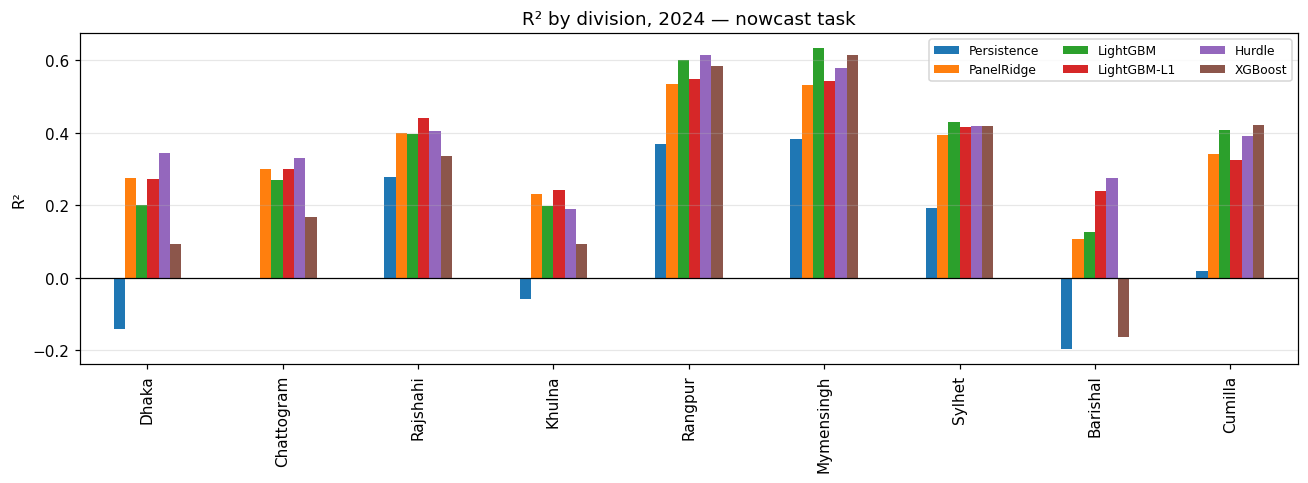

            Persistence  PanelRidge  LightGBM  LightGBM-L1  Hurdle  XGBoost
Dhaka            -0.142       0.274     0.202        0.271   0.344    0.092
Chattogram        0.000       0.301     0.271        0.301   0.330    0.167
Rajshahi          0.278       0.399     0.397        0.442   0.405    0.337
Khulna           -0.058       0.232     0.199        0.242   0.190    0.092
Rangpur           0.369       0.535     0.602        0.548   0.615    0.585
Mymensingh        0.383       0.531     0.634        0.542   0.579    0.614
Sylhet            0.192       0.393     0.430        0.416   0.418    0.419
Barishal         -0.197       0.107     0.127        0.238   0.275   -0.164
Cumilla           0.017       0.341     0.408        0.325   0.392    0.422


In [54]:
# Cell — R^2 by division, all models, final origin (bar chart, all 9 regions on one plot)
TASK_FOR_DIV_R2 = "nowcast"
te_o = panel[panel["year"] == FINAL_ORIGIN]
div_r2 = pd.DataFrame({
    m: [r2_score(te_o.loc[te_o.division == d, "burden"],
                 all_origin_preds[(TASK_FOR_DIV_R2, m, FINAL_ORIGIN)][(te_o.division == d).values])
        if te_o.loc[te_o.division == d, "burden"].var() > 0 else np.nan
        for d in DIVS]
    for m in MODELS}, index=DIVS)
fig, ax = plt.subplots(figsize=(12, 4.5))
div_r2.plot(kind="bar", ax=ax, color=[MODEL_COLORS[m] for m in MODELS])
ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel("R²"); ax.set_title(f"R² by division, {FINAL_ORIGIN} — {TASK_FOR_DIV_R2} task")
ax.legend(fontsize=8, ncol=3); ax.grid(alpha=0.3, axis="y")
plt.tight_layout(); plt.savefig(CFG.out_dir / "fig14_r2_by_division.png", dpi=600); plt.show()
print(div_r2.round(3).to_string())

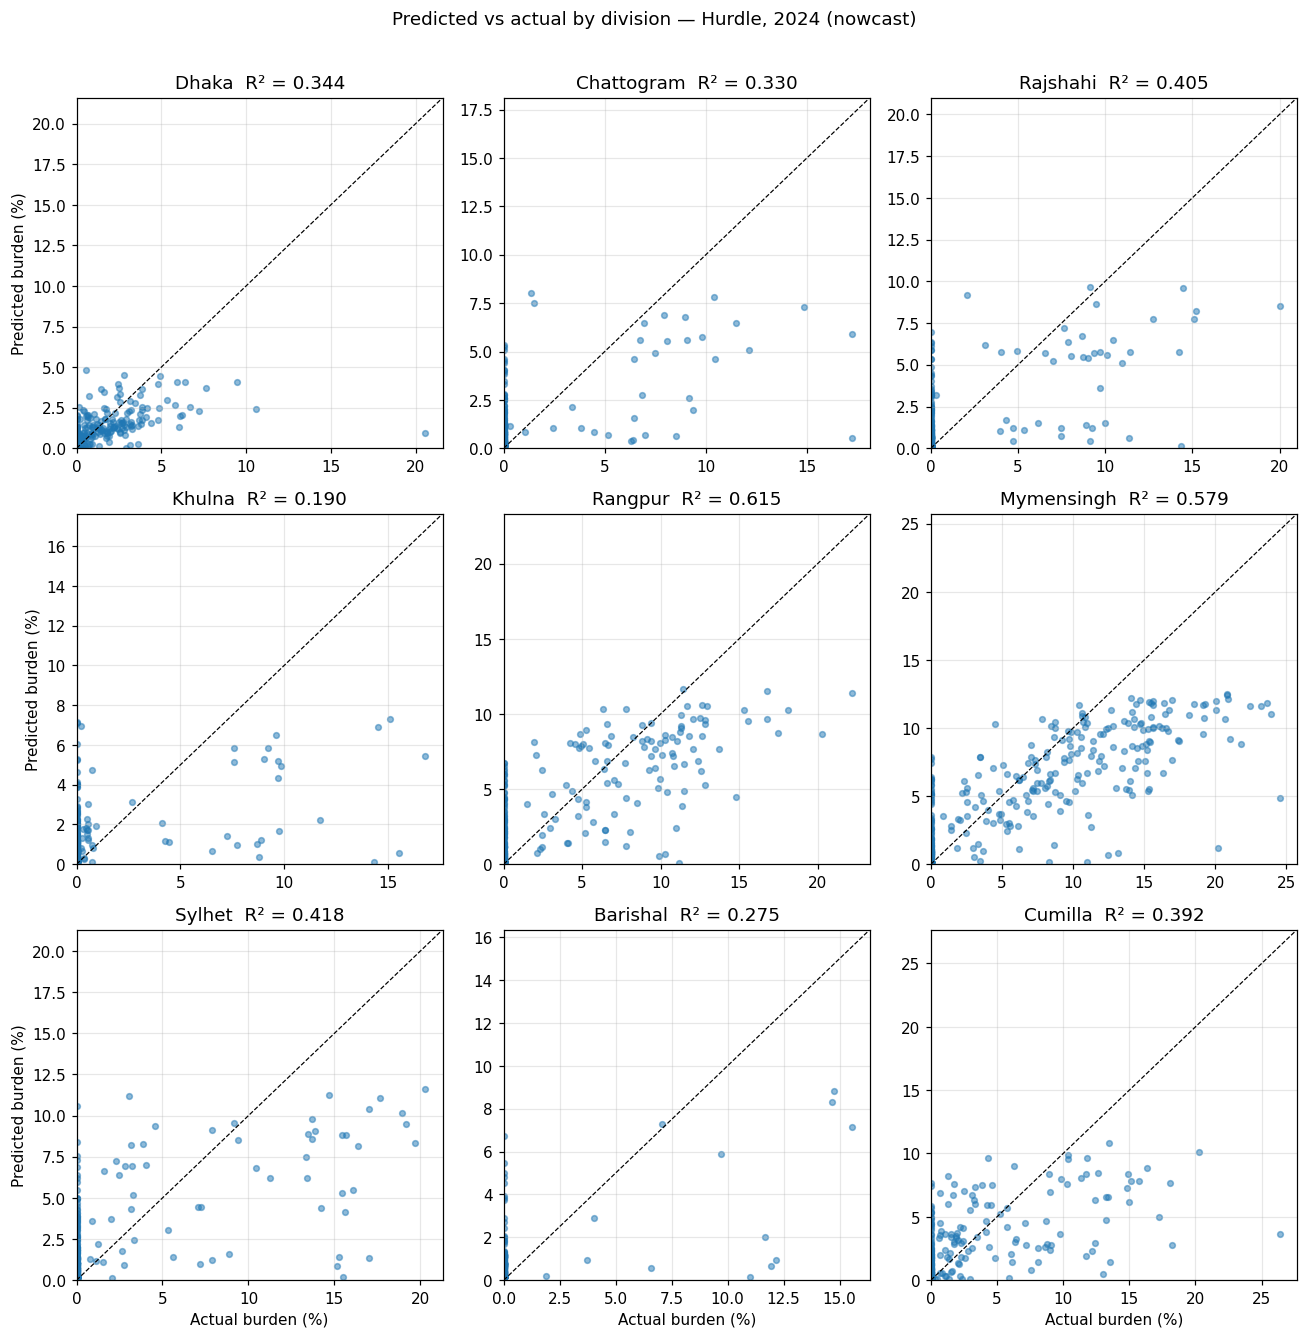

In [55]:
# Cell — predicted vs actual scatter, all 9 divisions, one focus model (final origin)
FOCUS_MODEL_GRID = "Hurdle"     # change to any model in MODELS
TASK_FOR_GRID = "nowcast"
te_o = panel[panel["year"] == FINAL_ORIGIN].reset_index(drop=True)
pred_o = all_origin_preds[(TASK_FOR_GRID, FOCUS_MODEL_GRID, FINAL_ORIGIN)]
fig, axes = plt.subplots(3, 3, figsize=(12, 12))
for ax, d in zip(axes.ravel(), DIVS):
    m = (te_o.division == d).values
    y, p = te_o.loc[m, "burden"].values, pred_o[m]
    lim = max(y.max(), p.max(), 1) * 1.05
    ax.scatter(y, p, s=14, alpha=0.5); ax.plot([0, lim], [0, lim], "k--", lw=0.8)
    r2 = r2_score(y, p) if y.var() > 0 else np.nan
    ax.set_title(f"{d}  R² = {r2:.3f}"); ax.set_xlim(0, lim); ax.set_ylim(0, lim); ax.grid(alpha=0.3)
for ax in axes[-1]: ax.set_xlabel("Actual burden (%)")
for ax in axes[:, 0]: ax.set_ylabel("Predicted burden (%)")
fig.suptitle(f"Predicted vs actual by division — {FOCUS_MODEL_GRID}, {FINAL_ORIGIN} ({TASK_FOR_GRID})", y=1.01)
plt.tight_layout(); plt.savefig(CFG.out_dir / "fig15_pred_vs_actual_by_division.png", dpi=600, bbox_inches="tight"); plt.show()

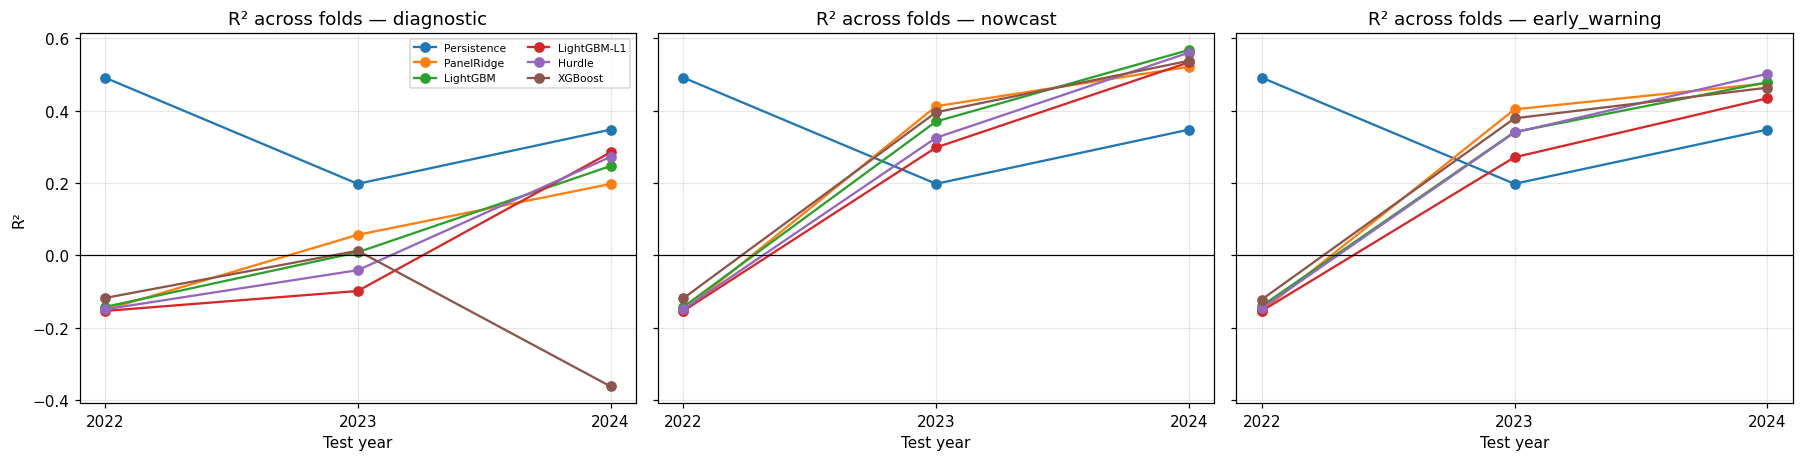

task   diagnostic                                                     early_warning                                                     nowcast                                                    
model      Hurdle LightGBM LightGBM-L1 PanelRidge Persistence XGBoost        Hurdle LightGBM LightGBM-L1 PanelRidge Persistence XGBoost  Hurdle LightGBM LightGBM-L1 PanelRidge Persistence XGBoost
origin                                                                                                                                                                                             
2022       -0.150   -0.143      -0.154     -0.151       0.491  -0.118        -0.146   -0.140      -0.154     -0.154       0.491  -0.122  -0.150   -0.143      -0.154     -0.154       0.491  -0.119
2023       -0.041    0.008      -0.099      0.057       0.198   0.013         0.340    0.341       0.271      0.403       0.198   0.379   0.325    0.370       0.298      0.412       0.198   0.396
2024        0.272   

In [56]:
# Cell — R^2 across rolling-origin folds (how much each fold improves R^2), per model/task
r2_fold = cv_table.pivot_table(index="origin", columns=["task", "model"], values="R2")
fig, axes = plt.subplots(1, len(FEATURE_SETS), figsize=(5.5 * len(FEATURE_SETS), 4.3), sharey=True)
for ax, task in zip(axes, FEATURE_SETS):
    sub = r2_fold[task][MODELS]
    for m in MODELS:
        ax.plot(sub.index.astype(str), sub[m], marker="o", label=m, color=MODEL_COLORS[m])
    ax.axhline(0, color="k", lw=0.8)
    ax.set_title(f"R² across folds — {task}"); ax.set_xlabel("Test year"); ax.grid(alpha=0.3)
axes[0].set_ylabel("R²"); axes[0].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.savefig(CFG.out_dir / "fig16_r2_across_folds.png", dpi=600); plt.show()
print(r2_fold.round(3).to_string())

MAE (pp) by division — 2024 fold, nowcast task:
model       Persistence  PanelRidge  LightGBM  LightGBM-L1  Hurdle  XGBoost
level                                                                      
Dhaka             0.907       0.843     0.895        0.715   0.737    0.993
Chattogram        0.735       1.059     1.157        0.685   1.062    1.311
Rajshahi          0.869       1.413     1.350        0.869   1.271    1.480
Khulna            0.750       1.204     1.222        0.716   1.167    1.372
Rangpur           1.836       2.096     1.784        1.623   1.809    1.825
Mymensingh        3.275       3.374     2.705        2.895   2.966    2.816
Sylhet            1.326       1.775     1.705        1.222   1.776    1.765
Barishal          0.450       0.808     0.976        0.435   0.803    1.220
Cumilla           1.901       1.988     1.855        1.607   1.830    1.849

MAE (pp) by stress level — 2024 fold:
model                           Persistence  PanelRidge  LightGBM  LightGBM-L

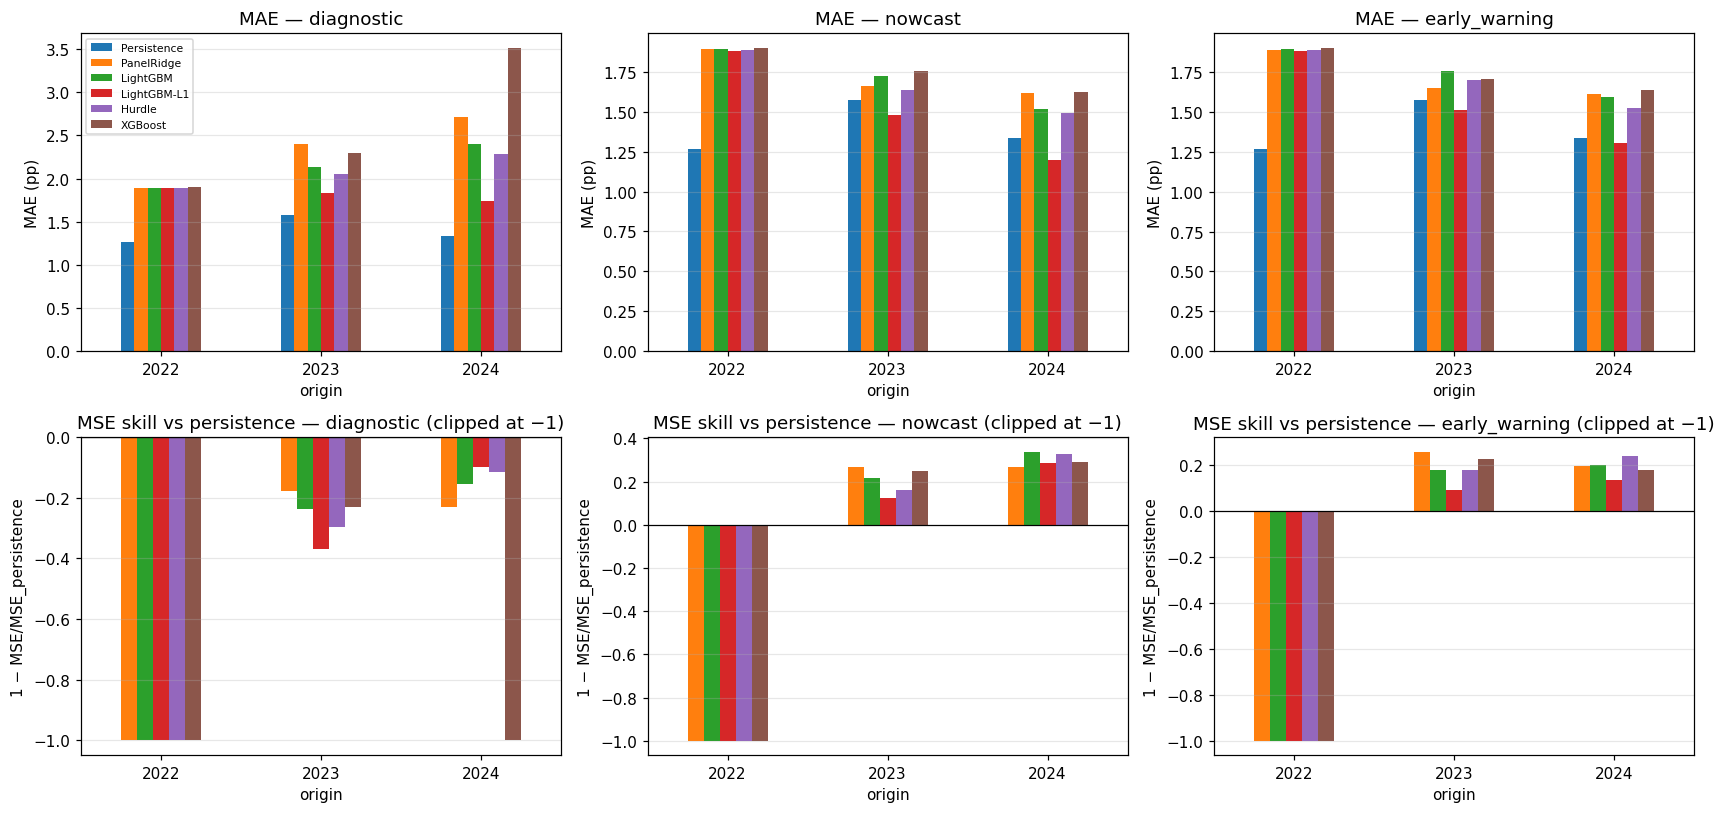

In [57]:
# ---- Error by division and by stress level for the final origin ----
te_final = panel[panel["year"] == FINAL_ORIGIN].reset_index(drop=True)
te_final["stress"] = np.where(te_final.groupby("Date")["burden"].transform("sum") > 0,
                              "shortfall day", "no-shortfall day")
err_rows = []
for task in FEATURE_SETS:
    for mname in MODELS:
        tmp = te_final.assign(ae=np.abs(te_final["burden"].values - final_preds[(task, mname)]))
        for d, v in tmp.groupby("division")["ae"].mean().items():
            err_rows.append(dict(task=task, model=mname, group="division", level=d, MAE=v))
        for s, v in tmp.groupby("stress")["ae"].mean().items():
            err_rows.append(dict(task=task, model=mname, group="stress", level=s, MAE=v))
err_table = pd.DataFrame(err_rows)
print(f"MAE (pp) by division — {FINAL_ORIGIN} fold, nowcast task:")
print(err_table.query("task=='nowcast' and group=='division'")
      .pivot(index="level", columns="model", values="MAE").loc[DIVS, MODELS].round(3).to_string())
print(f"\nMAE (pp) by stress level — {FINAL_ORIGIN} fold:")
print(err_table.query("group=='stress'").pivot_table(index=["task", "level"], columns="model", values="MAE")
      [MODELS].round(3).to_string())

# Hurdle detection quality at a 0.5 probability threshold (final origin)
from sklearn.metrics import precision_score, recall_score
for task in ("nowcast", "early_warning"):
    pz = final_scores[(task, "Hurdle")]; yb = te_final["burden"].values > 0
    print(f"\nHurdle detection ({task}, {FINAL_ORIGIN}): precision={precision_score(yb, pz >= 0.5):.3f} "
          f"recall={recall_score(yb, pz >= 0.5):.3f}  base rate={yb.mean():.3f}")

# Figure 6: rolling-origin MAE (top) and MSE skill vs persistence (bottom)
tasks = list(FEATURE_SETS)
MODEL_COLORS = dict(zip(MODELS, plt.cm.tab10.colors))       # same colour per model in every panel
fig, axes = plt.subplots(2, len(tasks), figsize=(5.2 * len(tasks), 7.5))
for j, task in enumerate(tasks):
    sub = cv_table[cv_table.task == task]
    sub.pivot(index="origin", columns="model", values="MAE")[MODELS].plot(
        kind="bar", ax=axes[0, j], rot=0, legend=(j == 0), color=[MODEL_COLORS[m] for m in MODELS])
    axes[0, j].set_title(f"MAE — {task}"); axes[0, j].set_ylabel("MAE (pp)"); axes[0, j].grid(alpha=0.3, axis="y")
    sk = sub[sub.model != "Persistence"].pivot(index="origin", columns="model", values="MSE_skill_vs_persistence")
    ml = [m for m in MODELS if m != "Persistence"]
    sk[ml].clip(lower=-1).plot(kind="bar", ax=axes[1, j], rot=0, legend=False, color=[MODEL_COLORS[m] for m in ml])
    axes[1, j].axhline(0, color="k", lw=0.8)
    axes[1, j].set_title(f"MSE skill vs persistence — {task} (clipped at −1)")
    axes[1, j].set_ylabel("1 − MSE/MSE_persistence"); axes[1, j].grid(alpha=0.3, axis="y")
axes[0, 0].legend(fontsize=7)
plt.tight_layout()
plt.savefig(CFG.out_dir / "fig6_rolling_origin_mae.png", dpi=600)
plt.show()

         task           removed    MAE     R2  MSE_skill_vs_persistence  delta_MAE  delta_R2
      nowcast (none) full model 1.5164 0.5676                    0.3375        NaN       NaN
      nowcast      − system_now 1.4672 0.5541                    0.3167    -0.0492   -0.0136
      nowcast     − lag_drivers 1.5644 0.5580                    0.3227     0.0480   -0.0097
      nowcast        − own_lags 2.4010 0.2468                   -0.1541     0.8846   -0.3208
      nowcast        − calendar 1.5096 0.5703                    0.3416    -0.0069    0.0027
early_warning (none) full model 1.5962 0.4786                    0.2011        NaN       NaN
early_warning     − lag_drivers 1.5987 0.4710                    0.1894     0.0025   -0.0076
early_warning      − lag_stress 1.6121 0.4726                    0.1919     0.0160   -0.0060
early_warning        − own_lags 1.8413 0.3924                    0.0690     0.2452   -0.0862
early_warning        − calendar 1.6446 0.4601                    0.172

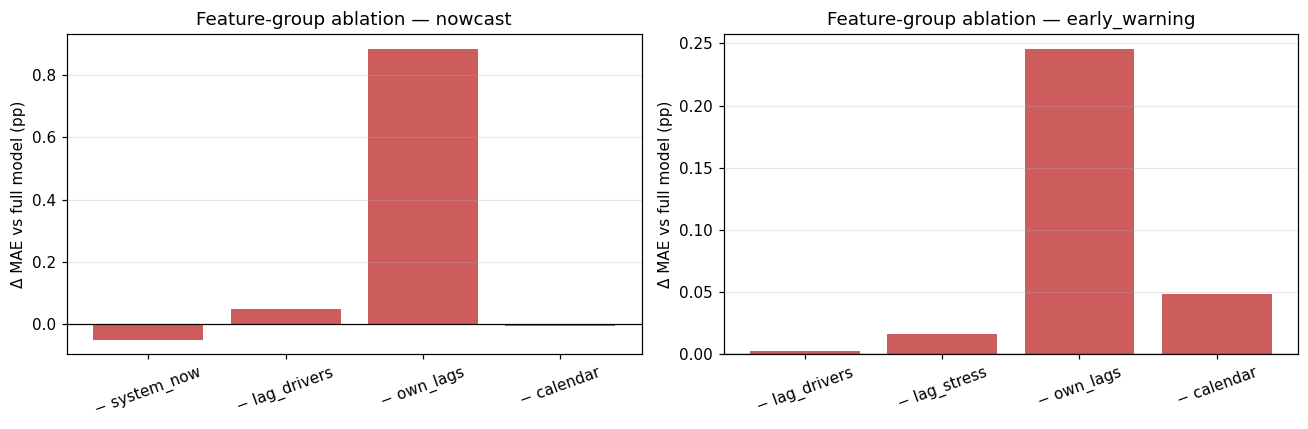

In [58]:
# Cell — Ablation 1: feature-group ablation (does each block actually help, or just correlate via SHAP?)
ABL_GROUPS = {
    "nowcast":       {"system_now": SYSTEM_NOW, "lag_drivers": LAG_DRIVERS, "own_lags": OWN_LAGS, "calendar": CALENDAR},
    "early_warning": {"lag_drivers": LAG_DRIVERS, "lag_stress": LAG_STRESS, "own_lags": OWN_LAGS, "calendar": CALENDAR},
}
tr_a = panel[panel["year"] < FINAL_ORIGIN]; te_a = panel[panel["year"] == FINAL_ORIGIN]
abl_rows = []
for task, groups in ABL_GROUPS.items():
    full_cols = FEATURE_SETS[task]["num"] + ["div_code"]
    m0, _ = lgbm_fit(tr_a, full_cols, "burden", objective="regression")
    base = evaluate_fold(te_a, np.clip(m0.predict(te_a[full_cols]), 0, 100), None)
    abl_rows.append(dict(task=task, removed="(none) full model", **base))
    for gname, gcols in groups.items():
        cols = [c for c in full_cols if c not in gcols]
        m, _ = lgbm_fit(tr_a, cols, "burden", objective="regression")
        s = evaluate_fold(te_a, np.clip(m.predict(te_a[cols]), 0, 100), None)
        s["delta_MAE"] = s["MAE"] - base["MAE"]; s["delta_R2"] = s["R2"] - base["R2"]
        abl_rows.append(dict(task=task, removed=f"− {gname}", **s))
ablation_table = pd.DataFrame(abl_rows).round(4)
ablation_table.to_csv(CFG.out_dir / "table_ablation_feature_groups.csv", index=False)
print(ablation_table[["task", "removed", "MAE", "R2", "MSE_skill_vs_persistence", "delta_MAE", "delta_R2"]].to_string(index=False))

fig, axes = plt.subplots(1, len(ABL_GROUPS), figsize=(6 * len(ABL_GROUPS), 4))
for ax, task in zip(axes, ABL_GROUPS):
    sub = ablation_table[(ablation_table.task == task) & (ablation_table.removed != "(none) full model")]
    ax.bar(sub["removed"], sub["delta_MAE"], color="indianred")
    ax.axhline(0, color="k", lw=0.8); ax.set_ylabel("Δ MAE vs full model (pp)")
    ax.set_title(f"Feature-group ablation — {task}"); ax.tick_params(axis="x", rotation=20); ax.grid(alpha=0.3, axis="y")
plt.tight_layout(); plt.savefig(CFG.out_dir / "fig17_ablation_feature_groups.png", dpi=600); plt.show()

         task                        variant    MAE  MAE_shortfall_days      R2    AUC
      nowcast Full hurdle (gate × regressor) 1.4912              2.1241  0.5603 0.8925
      nowcast    Gate only (Pr × train mean) 1.8624              2.6216  0.4142 0.9235
      nowcast       Regressor only (no gate) 5.5066              5.3046 -1.0939 0.6624
early_warning Full hurdle (gate × regressor) 1.5256              2.1375  0.5018 0.8642
early_warning    Gate only (Pr × train mean) 1.9143              2.6182  0.3805 0.8965
early_warning       Regressor only (no gate) 4.8654              4.6922 -0.7447 0.6433


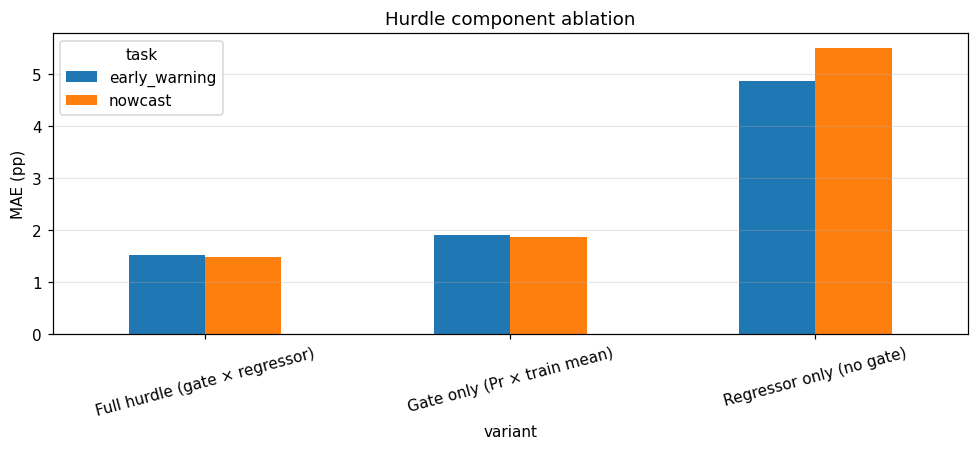

In [59]:
# Cell — Ablation 2: hurdle architecture (gate vs conditional regressor, isolated)
def hurdle_variants(tr, te, cols):
    hm = HurdleModel().fit(tr, cols)
    pz = hm.predict_proba(te[cols])
    pos_mean = tr.loc[tr["burden"] > 0, "burden"].mean()          # constant conditional mean
    return {
        "Full hurdle (gate × regressor)": hm.predict_proba(te[cols]) * hm.reg.predict(te[cols]),
        "Gate only (Pr × train mean)":     pz * pos_mean,
        "Regressor only (no gate)":        np.clip(hm.reg.predict(te[cols]), 0, None),
    }

hurdle_abl_rows = []
for task in ("nowcast", "early_warning"):
    cols = FEATURE_SETS[task]["num"] + ["div_code"]
    for vname, pred in hurdle_variants(tr_a, te_a, cols).items():
        hurdle_abl_rows.append(dict(task=task, variant=vname,
                                    **evaluate_fold(te_a, np.clip(pred, 0, 100), pred)))
hurdle_ablation_table = pd.DataFrame(hurdle_abl_rows).round(4)
hurdle_ablation_table.to_csv(CFG.out_dir / "table_ablation_hurdle.csv", index=False)
print(hurdle_ablation_table[["task", "variant", "MAE", "MAE_shortfall_days", "R2", "AUC"]].to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 4.2))
piv = hurdle_ablation_table.pivot(index="variant", columns="task", values="MAE")
piv.plot(kind="bar", ax=ax); ax.set_ylabel("MAE (pp)"); ax.set_title("Hurdle component ablation")
ax.tick_params(axis="x", rotation=15); ax.grid(alpha=0.3, axis="y")
plt.tight_layout(); plt.savefig(CFG.out_dir / "fig18_ablation_hurdle.png", dpi=600); plt.show()

### Early-stopping curves, predicted vs actual, and sample predictions

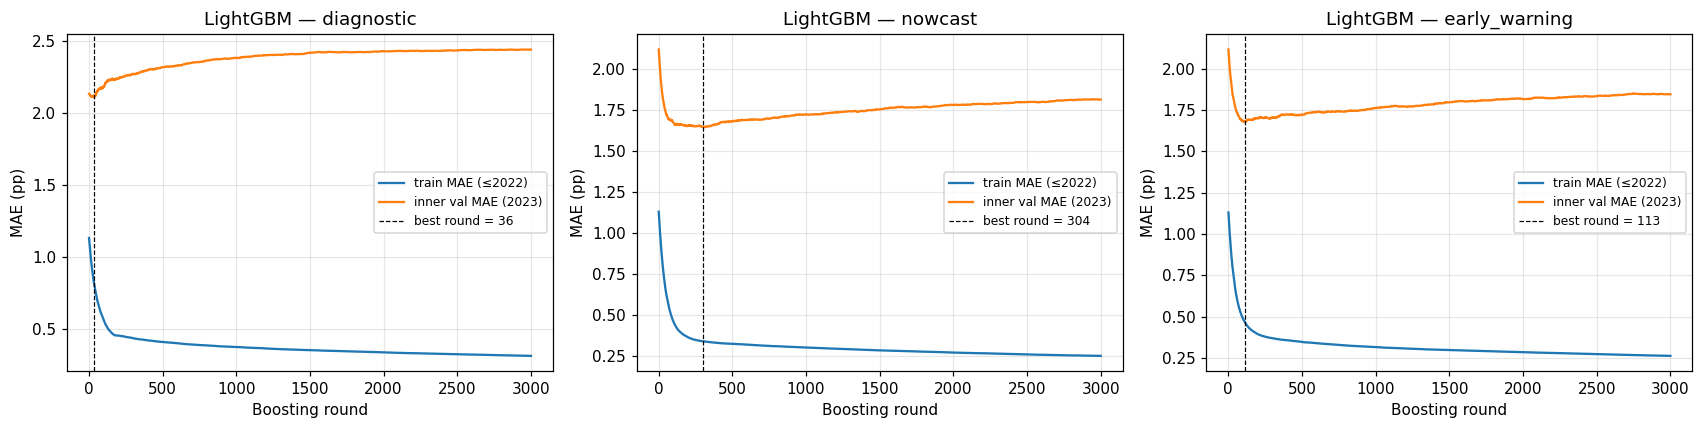

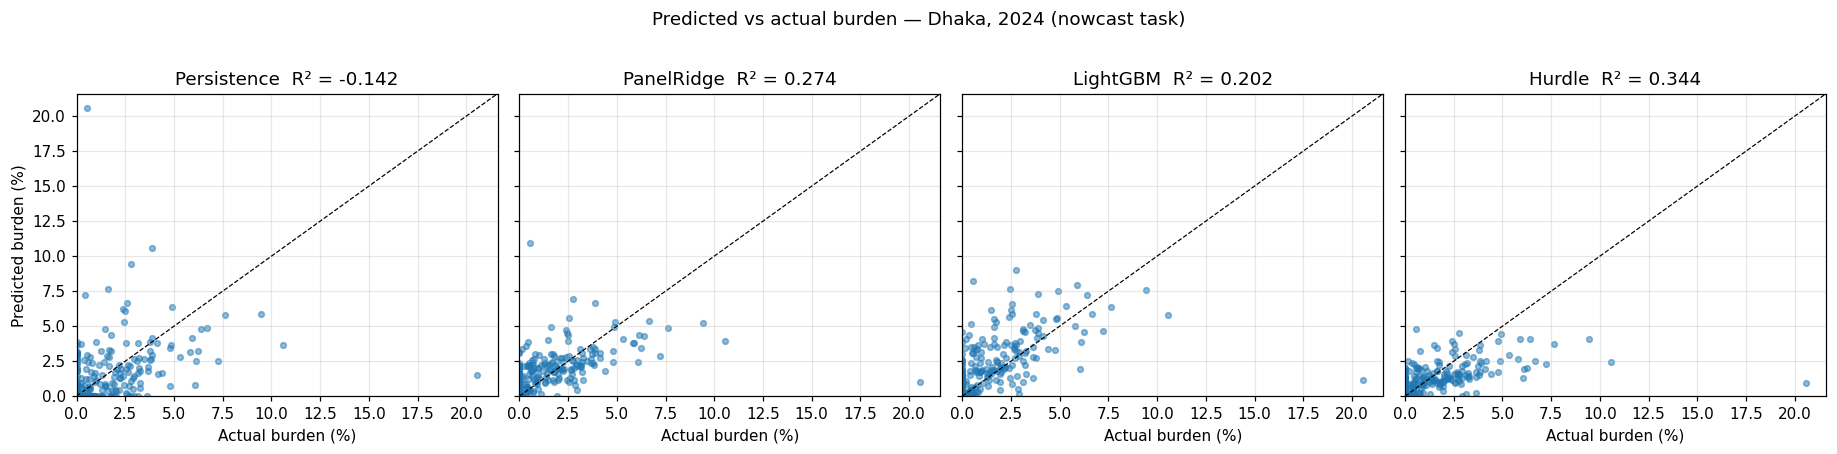

Sample daily predictions — Dhaka burden (%), nowcast task, 5 lowest + 5 highest actuals:

      Date  Actual  Persistence  PanelRidge  LightGBM  LightGBM-L1  Hurdle  XGBoost
2024-01-01    0.00         0.00        1.64      0.14         0.01    0.04     0.11
2024-01-02    0.00         0.00        1.21      0.14         0.01    0.04     0.11
2024-01-03    0.00         0.00        0.20      0.14         0.00    0.04     0.11
2024-01-04    0.00         0.00        0.00      0.14         0.00    0.04     0.11
2024-01-05    0.00         0.00        0.00      0.14         0.00    0.04     0.11
2024-10-18   20.57         1.54        0.99      1.17         0.69    0.97     1.03
2024-07-10   10.57         3.66        3.94      5.82         3.19    2.41     5.52
2024-09-09    9.45         5.90        5.26      7.55         4.81    4.11     7.12
2024-09-05    7.64         5.81        4.88      6.40         4.43    3.74     6.48
2024-08-15    7.24         2.49        2.85      4.68         2.48    

In [60]:
FOCUS_DIV = "Dhaka"   # used for the scatter and the sample table
tr_final = panel[panel["year"] < FINAL_ORIGIN]
tr_in, va_in = split_inner(tr_final)
fig, axes = plt.subplots(1, len(FEATURE_SETS), figsize=(5.2 * len(FEATURE_SETS), 4))
for ax, task in zip(axes, FEATURE_SETS):
    cols = FEATURE_SETS[task]["num"] + ["div_code"]
    rec = {}
    lgb.LGBMRegressor(**CFG.LGBM_PARAMS).fit(
        tr_in[cols], tr_in["burden"], eval_set=[(tr_in[cols], tr_in["burden"]), (va_in[cols], va_in["burden"])],
        eval_names=["train", "val"], eval_metric="l1", categorical_feature=["div_code"],
        callbacks=[lgb.record_evaluation(rec)])
    it = np.arange(1, len(rec["train"]["l1"]) + 1)
    best = int(np.argmin(rec["val"]["l1"])) + 1
    ax.plot(it, rec["train"]["l1"], label=f"train MAE (≤{va_in.year.max()-1})")
    ax.plot(it, rec["val"]["l1"], label=f"inner val MAE ({va_in.year.max()})")
    ax.axvline(best, color="k", ls="--", lw=0.8, label=f"best round = {best}")
    ax.set_xlabel("Boosting round"); ax.set_ylabel("MAE (pp)"); ax.set_title(f"LightGBM — {task}")
    ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(CFG.out_dir / "fig7_lightgbm_learning_curve.png", dpi=150)
plt.show()

mask_f = (te_final["division"] == FOCUS_DIV).values
y_true = te_final.loc[mask_f, "burden"].values
show = ["Persistence", "PanelRidge", "LightGBM", "Hurdle"]
fig, axes = plt.subplots(1, len(show), figsize=(4.2 * len(show), 4), sharex=True, sharey=True)
lim = max(y_true.max(), 1) * 1.05
for ax, mname in zip(axes, show):
    p = final_preds[("nowcast", mname)][mask_f]
    ax.scatter(y_true, p, s=14, alpha=0.5); ax.plot([0, lim], [0, lim], "k--", lw=0.8)
    ax.set_xlim(0, lim); ax.set_ylim(0, lim)
    ax.set_title(f"{mname}  R² = {r2_score(y_true, p):.3f}"); ax.set_xlabel("Actual burden (%)"); ax.grid(alpha=0.3)
axes[0].set_ylabel("Predicted burden (%)")
fig.suptitle(f"Predicted vs actual burden — {FOCUS_DIV}, {FINAL_ORIGIN} (nowcast task)", y=1.02)
plt.tight_layout()
plt.savefig(CFG.out_dir / "fig8_pred_vs_actual.png", dpi=600, bbox_inches="tight")
plt.show()

sample_df = pd.DataFrame({
    "Date": te_final.loc[mask_f, "Date"].dt.date.values,
    "Actual": y_true.round(2),
    **{m: final_preds[("nowcast", m)][mask_f].round(2) for m in MODELS},
})
shown = pd.concat([sample_df.nsmallest(5, "Actual"), sample_df.nlargest(5, "Actual")]).reset_index(drop=True)
print(f"Sample daily predictions — {FOCUS_DIV} burden (%), nowcast task, 5 lowest + 5 highest actuals:\n")
print(shown.to_string(index=False))

### Robustness: quarterly expanding-window origins

Yearly origins give only three test folds. Here the model is refitted at the start of every quarter from `QUARTERLY_START` to the end of 2024 (training on all earlier days, testing on the quarter). This shows whether any advantage over persistence is stable over time or concentrated in a few periods. FAST mode runs the nowcast task only; FULL mode adds early warning.

Quarterly origins finished in 16.0s

--- nowcast: MAE by quarter ---
model    Hurdle  LightGBM  Persistence
quarter                               
2022Q2    0.264     0.343        0.190
2022Q3    5.203     5.080        3.425
2022Q4    1.834     1.751        1.415
2023Q1    1.300     1.356        1.312
2023Q2    2.892     2.875        2.836
2023Q3    2.079     2.450        1.928
2023Q4    0.418     0.406        0.269
2024Q1    0.561     0.563        0.521
2024Q2    2.086     2.173        1.906
2024Q3    2.211     2.251        2.049
2024Q4    0.879     0.904        0.932
Hurdle     beats persistence on MAE in 2/11 quarters; median MSE skill = 0.272
LightGBM   beats persistence on MAE in 1/11 quarters; median MSE skill = 0.274



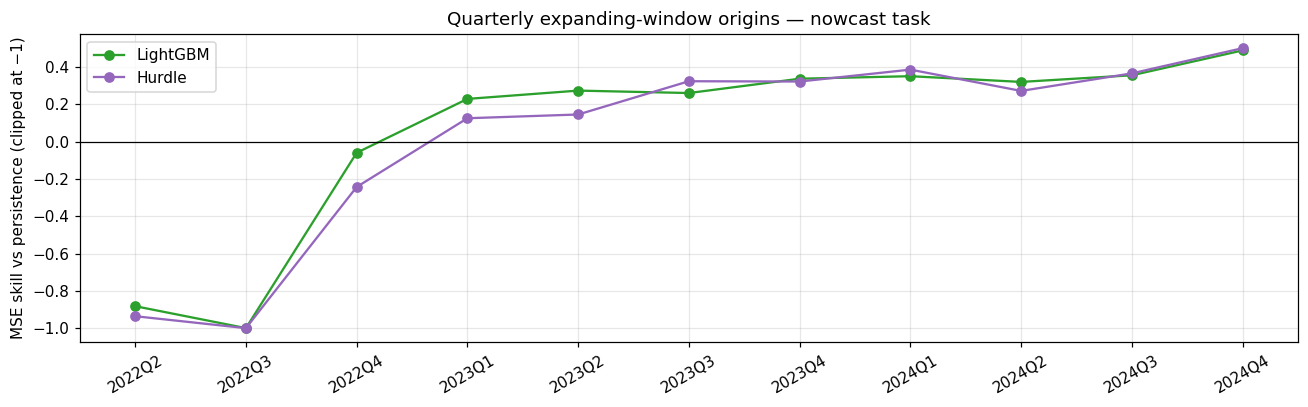

In [61]:
q_rows = []
if CFG.RUN_QUARTERLY:
    q_tasks = ["nowcast"] if CFG.MODE == "FAST" else ["nowcast", "early_warning"]
    q_models = ["Persistence", "LightGBM", "Hurdle"]
    t0 = time.time()
    for q in pd.period_range(CFG.QUARTERLY_START, panel["Date"].max(), freq="Q"):
        tr = panel[panel["Date"] < q.start_time]
        te = panel[(panel["Date"] >= q.start_time) & (panel["Date"] <= q.end_time)]
        if te.empty or te["burden"].sum() == 0:
            continue
        for task in q_tasks:
            for mname in q_models:
                p, s, _ = fit_predict(mname, task, tr, te)
                q_rows.append(dict(quarter=str(q), task=task, model=mname, **evaluate_fold(te, np.clip(p, 0, 100), s)))
    print(f"Quarterly origins finished in {time.time()-t0:.1f}s\n")
quarterly_table = pd.DataFrame(q_rows).round(4)
if not quarterly_table.empty:
    for task in quarterly_table.task.unique():
        sub = quarterly_table[quarterly_table.task == task]
        mae_q = sub.pivot(index="quarter", columns="model", values="MAE")
        print(f"--- {task}: MAE by quarter ---"); print(mae_q.round(3).to_string())
        for m in [c for c in mae_q.columns if c != "Persistence"]:
            wins = int((mae_q[m] < mae_q["Persistence"]).sum())
            skill = sub[sub.model == m]["MSE_skill_vs_persistence"]
            print(f"{m:10s} beats persistence on MAE in {wins}/{len(mae_q)} quarters; "
                  f"median MSE skill = {skill.median():.3f}")
        print()
    fig, ax = plt.subplots(figsize=(12, 3.8))
    sub = quarterly_table[quarterly_table.task == "nowcast"]
    for m in [c for c in sub.model.unique() if c != "Persistence"]:
        s = sub[sub.model == m].set_index("quarter")["MSE_skill_vs_persistence"]
        ax.plot(s.index, s.clip(lower=-1).values, marker="o", label=m, color=MODEL_COLORS.get(m))
    ax.axhline(0, color="k", lw=0.8); ax.set_ylabel("MSE skill vs persistence (clipped at −1)")
    ax.set_title("Quarterly expanding-window origins — nowcast task"); ax.legend(); ax.grid(alpha=0.3)
    plt.xticks(rotation=30); plt.tight_layout()
    plt.savefig(CFG.out_dir / "fig6b_quarterly_skill.png", dpi=600)
    plt.show()

## Explainability: SHAP on the Final Nonlinear Model

SHAP is applied to the final LightGBM models (trained on years < final origin, explained on the final origin). The **diagnostic** model — the one without own burden history — is the explanatory result: it answers *which operating conditions are associated with observed burden*. The nowcast and early-warning attributions are printed for completeness and are expected to be dominated by own burden history. Features are aggregated into interpretable groups.

In [62]:
import shap

def feature_group(f):
    if f.startswith("gas"):        return "Gas/LF"
    if f.startswith("coal"):       return "Coal"
    if f.startswith("hydro"):      return "Kaptai hydro"
    if f.startswith("maint"):      return "Maintenance"
    if f.startswith("nat_demand"): return "National demand"
    if f.startswith("nat_gap"):    return "Lagged national shortfall"
    if f.startswith("burden"):     return "Own burden history"
    if f == "temp":                return "Temperature"
    if f in ("Holiday_cat", "dow", "month"): return "Calendar"
    return "Division structure"

shap_tables, shap_store = {}, {}
for task in FEATURE_SETS:
    model = final_models[(task, "LightGBM")]
    cols = FEATURE_SETS[task]["num"] + ["div_code"]
    X_te = te_final[cols]
    sv = shap.TreeExplainer(model).shap_values(X_te)
    shap_store[task] = (sv, X_te)
    abs_df = pd.DataFrame(np.abs(sv), columns=cols)
    grp = abs_df.T.groupby([feature_group(c) for c in cols]).sum().T
    grp["Division"] = te_final["division"].values
    by_div = grp.groupby("Division").mean().loc[DIVS]
    by_div = 100 * by_div.div(by_div.sum(axis=1), axis=0)
    overall = 100 * grp.drop(columns="Division").mean() / grp.drop(columns="Division").mean().sum()
    shap_tables[task] = by_div.round(1)
    print(f"--- {task}: overall share of mean |SHAP| (%) ---")
    print(overall.sort_values(ascending=False).round(1).to_string())
    print()
shap_table = shap_tables["diagnostic"]
print("Diagnostic task — share of mean |SHAP| by division (%):")
print(shap_table.to_string())

--- diagnostic: overall share of mean |SHAP| (%) ---
National demand       59.5
Gas/LF                18.5
Division structure    15.8
Maintenance            5.2
Kaptai hydro           0.4
Calendar               0.3
Coal                   0.3
Temperature            0.1

--- nowcast: overall share of mean |SHAP| (%) ---
Own burden history    59.4
National demand       23.5
Division structure     7.6
Gas/LF                 6.2
Maintenance            1.5
Calendar               1.1
Kaptai hydro           0.3
Coal                   0.2
Temperature            0.2

--- early_warning: overall share of mean |SHAP| (%) ---
Own burden history           68.8
Lagged national shortfall    15.9
Division structure            4.2
National demand               4.2
Calendar                      3.2
Gas/LF                        2.3
Maintenance                   1.4

Diagnostic task — share of mean |SHAP| by division (%):
            Calendar  Coal  Division structure  Gas/LF  Kaptai hydro  Maintenance  Na

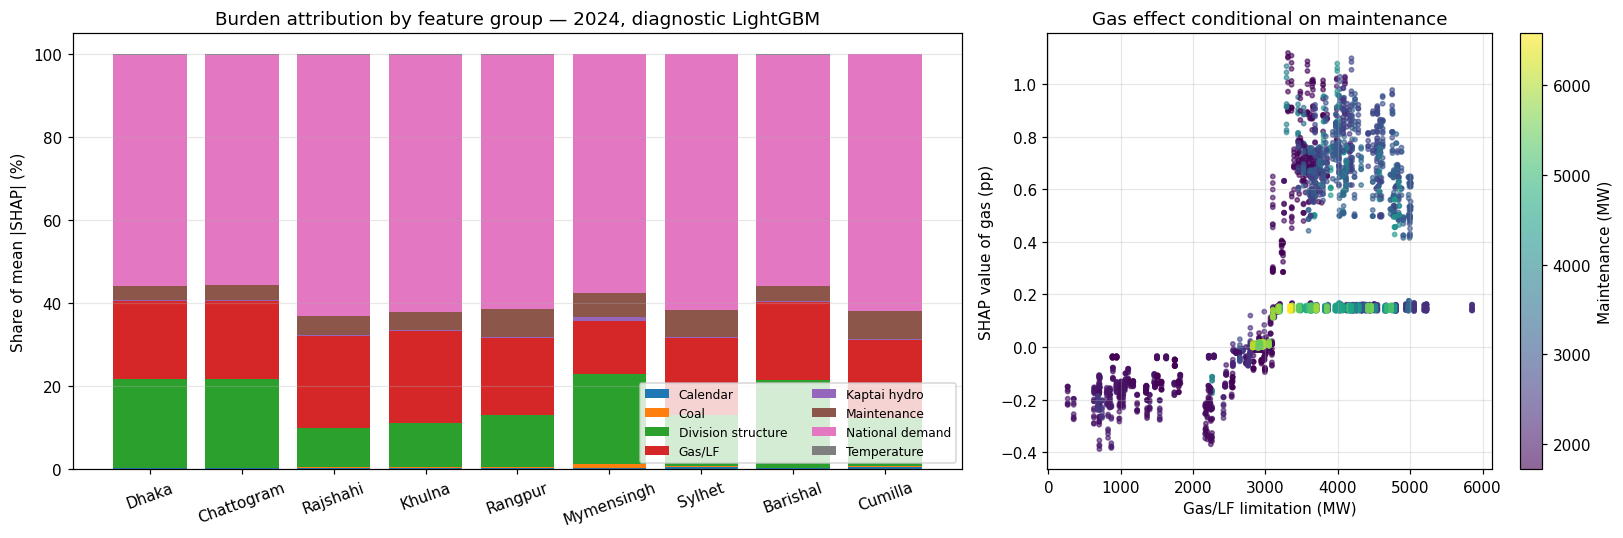

In [63]:
# Figure 9: stacked SHAP groups per division (diagnostic) + gas × maintenance interaction view
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.6, 1]})
bottom = np.zeros(len(shap_table))
for c in shap_table.columns:
    axes[0].bar(shap_table.index, shap_table[c], bottom=bottom, label=c)
    bottom += shap_table[c].values
axes[0].set_ylabel("Share of mean |SHAP| (%)")
axes[0].set_title(f"Burden attribution by feature group — {FINAL_ORIGIN}, diagnostic LightGBM")
axes[0].legend(fontsize=8, ncol=2, loc="lower right"); axes[0].tick_params(axis="x", rotation=20)
axes[0].grid(alpha=0.3, axis="y")

sv, X_te = shap_store["diagnostic"]
gi = list(X_te.columns).index("gas")
sc = axes[1].scatter(X_te["gas"], sv[:, gi], c=X_te["maint"], cmap="viridis", s=8, alpha=0.6)
plt.colorbar(sc, ax=axes[1], label="Maintenance (MW)")
axes[1].set_xlabel("Gas/LF limitation (MW)"); axes[1].set_ylabel("SHAP value of gas (pp)")
axes[1].set_title("Gas effect conditional on maintenance"); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(CFG.out_dir / "fig9_shap_attribution.png", dpi=600)
plt.show()

## Division Vulnerability (Relative Curtailment Burden)

Burden is compared as a **rate** ($G_{d,t}/D_{d,t}$), not in MW — a large division naturally loses more MW. We report, per division and regime: mean burden, share of days curtailed, 95th-percentile burden, longest run of consecutive curtailed days, and the gas sensitivity $\beta^{Gas}_{d,r}$ from Section 7. Without customer counts, critical loads or industry mix, this is **burden equity / allocation disparity**, not social fairness.

Division vulnerability (crisis & recovery regimes):

  regime   Division  mean_burden  pct_days_curtailed  p95_burden  longest_run_days  beta_gas
  crisis Mymensingh        5.002              45.304      19.937                42     1.306
  crisis    Rangpur        2.429              23.066      14.984                14     0.604
  crisis     Sylhet        2.363              22.514      16.635                11     0.640
  crisis    Cumilla        2.246              29.282      13.712                29     0.533
  crisis   Rajshahi        1.498              18.370      11.079                13     0.582
  crisis     Khulna        1.383              15.608      10.932                20     0.484
  crisis      Dhaka        0.828              27.624       5.353                19     0.479
  crisis Chattogram        0.686               8.149       5.288                 4     0.263
  crisis   Barishal        0.198               2.072       0.000                 5     0.230
recovery Mymensin

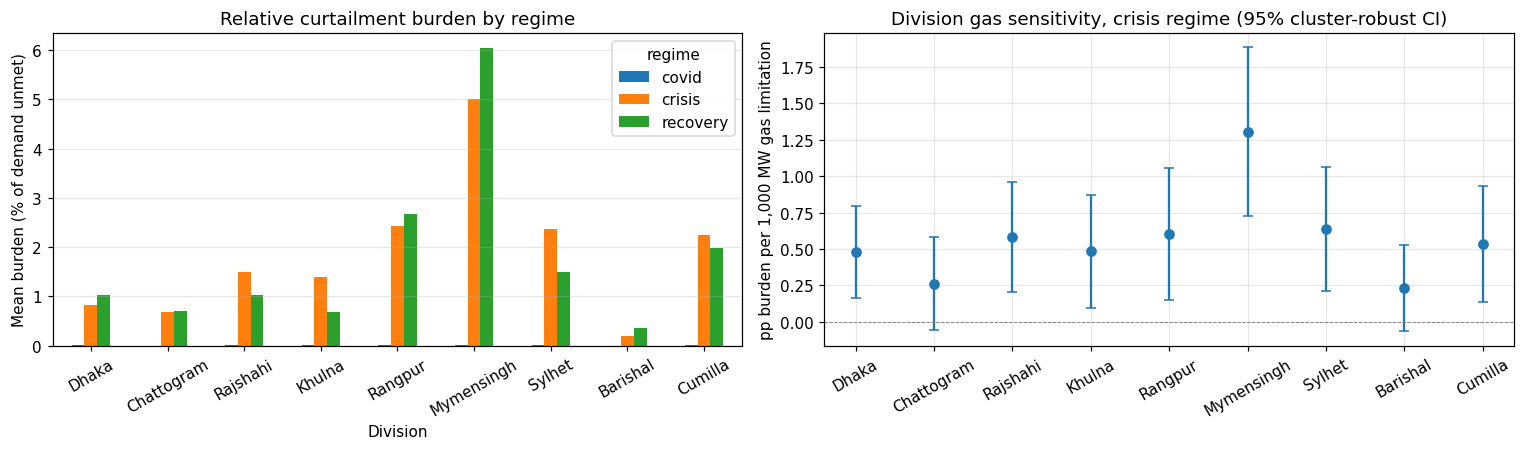

In [64]:
def longest_run(active: np.ndarray) -> int:
    best = cur = 0
    for a in active:
        cur = cur + 1 if a else 0
        best = max(best, cur)
    return best

vul_rows = []
for r, g in panel.groupby("regime"):
    for d in DIVS:
        s = g[g["division"] == d].sort_values("Date")
        vul_rows.append(dict(regime=r, Division=d,
                             mean_burden=s["burden"].mean(),
                             pct_days_curtailed=100 * (s["burden"] > 0).mean(),
                             p95_burden=s["burden"].quantile(0.95),
                             longest_run_days=longest_run((s["burden"] > 0).values)))
vulnerability = (pd.DataFrame(vul_rows)
                 .merge(gas_sens[["regime", "Division", "beta_gas"]], on=["regime", "Division"])
                 .round(3))
crisis_vul = vulnerability[vulnerability.regime != "covid"].sort_values(["regime", "mean_burden"], ascending=[True, False])
print("Division vulnerability (crisis & recovery regimes):\n")
print(crisis_vul.to_string(index=False))

# Figure 10
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
piv = vulnerability.pivot(index="Division", columns="regime", values="mean_burden").loc[DIVS]
piv.plot(kind="bar", ax=axes[0], rot=30)
axes[0].set_ylabel("Mean burden (% of demand unmet)"); axes[0].set_title("Relative curtailment burden by regime")
axes[0].grid(alpha=0.3, axis="y")
gc = gas_sens[gas_sens.regime == "crisis"].set_index("Division").loc[DIVS]
axes[1].errorbar(range(len(DIVS)), gc["beta_gas"], yerr=[gc["beta_gas"] - gc["ci_low"], gc["ci_high"] - gc["beta_gas"]],
                 fmt="o", capsize=3)
axes[1].axhline(0, color="grey", lw=0.6, ls="--")
axes[1].set_xticks(range(len(DIVS))); axes[1].set_xticklabels(DIVS, rotation=30)
axes[1].set_ylabel("pp burden per 1,000 MW gas limitation")
axes[1].set_title("Division gas sensitivity, crisis regime (95% cluster-robust CI)"); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(CFG.out_dir / "fig10_division_vulnerability.png", dpi=600)
plt.show()

##  Fair-Curtailment Allocation (Counterfactual OR Layer)

**Required curtailment.** $S_t=\sum_d \max(D_{d,t}-S_{d,t},0)$ — the observed divisional imbalance (not gas+coal+hydro). Every allocation distributes exactly this $S_t$ (the MILP may over-curtail slightly, penalised and reported), so allocations differ only in *who* bears it.

**Demonstrated delivery capacity.** Without topology, a data-driven feasibility proxy is used: division $d$ cannot be supplied more than the maximum it demonstrably received in the trailing `CAPACITY_WINDOW_DAYS` (including today), giving a lower bound $x_{d,t}\ge LB_{d,t}=\max(0, D_{d,t}-\max_{\tau\in[t-W,t]}S_{d,\tau})$. Observed allocations satisfy it by construction.

**Allocations compared.**
1. **BPDB observed**: $x_{d,t}=\max(D_{d,t}-S_{d,t},0)$.
2. **Proportional to demand**: $x_{d,t}=S_t D_{d,t}/\sum_d D_{d,t}$. Note that this *is* the equal-burden-rate allocation, and without extra constraints the min-max burden LP has exactly this solution — so a separate "equal-burden" benchmark would be redundant.
3. **Equal MW**: $x_{d,t}=S_t/9$ (capped at $D_{d,t}$), the absolute-MW contrast.
4. **Min-max burden LP (capacity-aware)**: $\min z$ s.t. $x_d\le zD_d$, $\sum_d x_d=S_t$, $LB_d\le x_d\le D_d$. Solved with HiGHS; the lexicographic (water-filling) optimum is selected among ties and checked against $z^*$.
5. **Temporal-fairness MILP** (rolling horizon of `MILP_HORIZON_DAYS`, cumulative state carried within each year):

$$\min\; w_c Z^{cum} + w_r (Z^{cum}-Z^{min}) + \tfrac{w_d}{H}\sum_t z_t + w_o\,\tfrac{100\sum_t o_t}{\sum_t S_t} + w_{rot}\sum_{d,t}s_{d,t}$$

subject to $\sum_d x_{d,t}=S_t+o_t$; $\;m D_{d,t}y_{d,t}\le x_{d,t}\le D_{d,t}y_{d,t}$ (minimum activation block, $y\in\{0,1\}$); $\;LB_{d,t}\le x_{d,t}$; $\;100x_{d,t}/D_{d,t}\le z_t$; $\;Z^{min}\le 100\,\frac{C_d+\sum_t x_{d,t}}{\bar D_d+\sum_t D_{d,t}}\le Z^{cum}$ (cumulative burden rate incl. history); $\;\sum_{\tau=t-K}^{t}y_{d,\tau}\le K+s_{d,t}$ (rotation: at most $K$ consecutive curtailed days, soft).

The MILP is where binary decisions are genuinely needed (switching areas on/off in blocks, rotation). Division "vulnerability weights" are **not** used, because weights estimated from the same burden data would be circular. Consecutive-day counts use the observed row sequence (missing dates are treated as adjacent).

In [65]:
# ---- allocation data ----
for d in DIVS:
    df[f"{d}_cap"] = (df.set_index("Date")[f"{d}_supply"].reindex(FULL_RANGE)
                        .rolling(CFG.CAPACITY_WINDOW_DAYS, min_periods=1).max()
                        .reindex(df["Date"]).values)
A = df[df["year"].isin(CFG.alloc_years)].reset_index(drop=True)
Dm    = A[DEMAND_COLS].to_numpy(float)
X_obs = A[GAP_COLS].to_numpy(float)
S_req = X_obs.sum(axis=1)
LB    = np.clip(Dm - A[[f"{d}_cap" for d in DIVS]].to_numpy(float), 0, None)
YRS   = A["year"].to_numpy()
SD    = S_req > 0
assert (LB <= X_obs + 1e-9).all(), "Observed allocation violates its own capacity bound"
print(f"Allocation period {CFG.alloc_years}: {len(A)} days, {SD.sum()} shortage days, "
      f"mean S_t on shortage days = {S_req[SD].mean():.0f} MW")
print(f"Days where the capacity bound is active (ΣLB > 0): {(LB.sum(1) > 0).sum()}  "
      f"(mean ΣLB/S_t on those days = {np.mean(LB.sum(1)[LB.sum(1)>0] / S_req[LB.sum(1)>0]):.2f})")

# ---- benchmark allocations ----
def alloc_proportional(S, D):
    return S[:, None] * D / D.sum(axis=1, keepdims=True)

def _bisect(fn, target, lo, hi, iters=100):
    for _ in range(iters):
        mid = 0.5 * (lo + hi)
        lo, hi = (mid, hi) if fn(mid) < target else (lo, mid)
    return 0.5 * (lo + hi)

def alloc_equal_mw(S, D):
    X = np.zeros_like(D)
    for t in np.where(S > 0)[0]:
        m = _bisect(lambda v: np.minimum(v, D[t]).sum(), S[t], 0.0, D[t].max())
        X[t] = np.minimum(m, D[t])
    return X

def waterfill_burden(s, d, lb):
    # Lexicographic min-max burden: x_d = clip(r*D_d, LB_d, D_d), with sum x = s.
    r = _bisect(lambda v: np.clip(v * d, lb, d).sum(), s, 0.0, 1.0)
    return np.clip(r * d, lb, d)

def solve_minmax_lp(s, d, lb):
    n = len(d)
    c = np.r_[np.zeros(n), 1.0]
    A_ub = np.hstack([np.eye(n), -d[:, None]])                  # x_d - z D_d <= 0
    A_eq = np.r_[np.ones(n), 0.0][None, :]                     # sum x = s
    bounds = [(lb[i], d[i]) for i in range(n)] + [(0, 1)]
    res = linprog(c, A_ub=A_ub, b_ub=np.zeros(n), A_eq=A_eq, b_eq=[s], bounds=bounds, method="highs")
    if res.status != 0:
        raise RuntimeError(f"LP failed: {res.message}")
    z_star = res.x[-1]
    x = waterfill_burden(s, d, lb)                              # tie-break among optimal solutions
    assert (x / d).max() <= z_star + 1e-6, "water-filling solution is not min-max optimal"
    return x, z_star

X_prop  = alloc_proportional(S_req, Dm)
X_eqmw  = alloc_equal_mw(S_req, Dm)
X_lp    = np.zeros_like(Dm); Z_lp = np.zeros(len(A))
t0 = time.time()
for t in np.where(SD)[0]:
    X_lp[t], Z_lp[t] = solve_minmax_lp(S_req[t], Dm[t], LB[t])
print(f"Min-max LP solved on {SD.sum()} days in {time.time()-t0:.1f}s")
for name, X in [("Proportional", X_prop), ("Equal MW", X_eqmw), ("Min-max LP", X_lp)]:
    assert np.allclose(X.sum(1), S_req, atol=1e-4), f"{name} does not allocate S_t"

Allocation period (2024,): 357 days, 219 shortage days, mean S_t on shortage days = 374 MW
Days where the capacity bound is active (ΣLB > 0): 151  (mean ΣLB/S_t on those days = 0.47)
Min-max LP solved on 219 days in 0.6s


In [66]:
# ---- temporal-fairness MILP (rolling horizon) ----
def solve_milp_window(Dw, Sw, LBw, cum_x, cum_D, y_hist, K, cfg):
    H, n = Dw.shape
    nx = H * n
    ix  = lambda t, d: t * n + d
    iy  = lambda t, d: nx + t * n + d
    is_ = lambda t, d: 2 * nx + t * n + d
    iov = lambda t: 3 * nx + t
    iz  = lambda t: 3 * nx + H + t
    iZc, iZm = 3 * nx + 2 * H, 3 * nx + 2 * H + 1
    nvar = iZm + 1

    c = np.zeros(nvar)
    c[iZc] = cfg.MILP_W_CUM + cfg.MILP_W_RANGE
    c[iZm] = -cfg.MILP_W_RANGE
    for t in range(H):
        c[iz(t)]  = cfg.MILP_W_DAY / H
        c[iov(t)] = cfg.MILP_W_OVER * 100.0 / max(Sw.sum(), 1e-9)
        for d in range(n):
            c[is_(t, d)] = cfg.MILP_W_ROT

    lb = np.zeros(nvar); ub = np.full(nvar, np.inf); integ = np.zeros(nvar)
    for t in range(H):
        active_day = Sw[t] > 0
        for d in range(n):
            lb[ix(t, d)] = LBw[t, d]
            ub[ix(t, d)] = Dw[t, d] if active_day else 0.0
            ub[iy(t, d)] = 1.0 if active_day else 0.0
            integ[iy(t, d)] = 1
            ub[is_(t, d)] = (K + 1) if K is not None else 0.0
        ub[iz(t)] = 100.0
    ub[iZc] = ub[iZm] = 100.0

    rows, cols, vals, lo, hi = [], [], [], [], []
    r = 0
    def add(entries, l, h):
        nonlocal r
        for j, v in entries:
            rows.append(r); cols.append(j); vals.append(v)
        lo.append(l); hi.append(h); r += 1

    Dcum = cum_D + Dw.sum(axis=0)
    for t in range(H):
        add([(ix(t, d), 1.0) for d in range(n)] + [(iov(t), -1.0)], Sw[t], Sw[t])       # coverage
        for d in range(n):
            add([(ix(t, d), 1.0), (iy(t, d), -Dw[t, d])], -np.inf, 0.0)                  # x <= D y
            add([(ix(t, d), 1.0), (iy(t, d), -cfg.MILP_MIN_ACTIVE_FRAC * Dw[t, d])], 0.0, np.inf)  # x >= m D y
            add([(ix(t, d), 100.0 / Dw[t, d]), (iz(t), -1.0)], -np.inf, 0.0)             # daily max burden
    for d in range(n):
        coef = 100.0 / Dcum[d]; base = 100.0 * cum_x[d] / Dcum[d]
        add([(ix(t, d), coef) for t in range(H)] + [(iZc, -1.0)], -np.inf, -base)       # cum <= Zc
        add([(ix(t, d), -coef) for t in range(H)] + [(iZm, 1.0)], -np.inf, base)        # Zm <= cum
    if K is not None:
        for t in range(H):
            for d in range(n):
                entries, hist = [], 0.0
                for tau in range(t - K, t + 1):
                    if tau >= 0:
                        entries.append((iy(tau, d), 1.0))
                    elif y_hist is not None and len(y_hist) + tau >= 0:
                        hist += y_hist[len(y_hist) + tau, d]
                entries.append((is_(t, d), -1.0))
                add(entries, -np.inf, K - hist)

    Amat = sparse.csr_matrix((vals, (rows, cols)), shape=(r, nvar))
    res = milp(c, constraints=LinearConstraint(Amat, lo, hi), integrality=integ, bounds=Bounds(lb, ub),
               options={"time_limit": cfg.MILP_TIME_LIMIT_S, "mip_rel_gap": cfg.MILP_GAP, "disp": False})
    if res.x is None:
        return None, None, None, res.status
    x = res.x[:nx].reshape(H, n); y = np.round(res.x[nx:2 * nx].reshape(H, n)).astype(int)
    s = res.x[2 * nx:3 * nx].reshape(H, n)
    return x, y, s, res.status

def run_temporal_milp(Dm, S_req, LB, years, K, cfg):
    T, n = Dm.shape; H = cfg.MILP_HORIZON_DAYS
    X = np.zeros((T, n)); Y = np.zeros((T, n), dtype=int); rot_viol = 0.0; status = []
    for yr in np.unique(years):
        idx = np.where(years == yr)[0]
        cum_x = np.zeros(n); cum_D = np.zeros(n)
        for w0 in range(0, len(idx), H):
            w = idx[w0:w0 + H]
            y_hist = Y[idx[max(0, w0 - (K or 0)):w0]] if (K is not None and w0 > 0) else None
            if S_req[w].sum() > 0:
                x, y, s, st = solve_milp_window(Dm[w], S_req[w], LB[w], cum_x, cum_D, y_hist, K, cfg)
                status.append(st)
                if x is None:                                    # fallback: capacity-aware water-filling
                    x = np.array([waterfill_burden(S_req[t], Dm[t], LB[t]) if S_req[t] > 0 else np.zeros(n) for t in w])
                    y = (x > 1e-6).astype(int); s = np.zeros_like(x)
                X[w] = np.clip(x, 0, None); Y[w] = y; rot_viol += float(np.round(s).sum())
            cum_x += X[w].sum(axis=0); cum_D += Dm[w].sum(axis=0)
    return X, Y, dict(rotation_violation_days=rot_viol, n_windows=len(status),
                      n_optimal=int(sum(s == 0 for s in status)),
                      n_time_limit=int(sum(s == 1 for s in status)))

t0 = time.time()
X_milp, Y_milp, milp_info = run_temporal_milp(Dm, S_req, LB, YRS, CFG.MILP_MAX_CONSEC_DAYS, CFG)
print(f"Temporal MILP (K={CFG.MILP_MAX_CONSEC_DAYS}) solved in {time.time()-t0:.1f}s  {milp_info}")
assert (X_milp.sum(1) >= S_req - 1e-4).all(), "MILP under-covers S_t"
assert (X_milp >= LB - 1e-4).all(), "MILP violates capacity bound"

Temporal MILP (K=3) solved in 13.8s  {'rotation_violation_days': 149.0, 'n_windows': 43, 'n_optimal': 43, 'n_time_limit': 0}


In [67]:
# ---- equity metrics on burden rates ----
def jain_index(x):
    x = np.asarray(x, dtype=float); x = x[~np.isnan(x)]
    if x.sum() == 0: return 1.0
    return (x.sum() ** 2) / (len(x) * (x ** 2).sum() + 1e-12)

def gini(x):
    x = np.asarray(x, dtype=float); x = x[~np.isnan(x)]
    if x.sum() == 0: return 0.0
    x = np.sort(x); n = len(x)
    cum = np.cumsum(x)
    return (n + 1 - 2 * cum.sum() / cum[-1]) / n

def atkinson(x, eps=0.5):
    x = np.asarray(x, dtype=float); x = x[~np.isnan(x)]
    mean = x.mean()
    if mean == 0: return 0.0
    if eps == 1.0:
        x = x + 1e-9
        return 1 - np.exp(np.log(x).mean()) / mean
    return 1 - ((x ** (1 - eps)).mean()) ** (1 / (1 - eps)) / mean

def cumulative_burden(X, Dm, years):
    return {yr: 100 * X[years == yr].sum(0) / Dm[years == yr].sum(0) for yr in np.unique(years)}

def allocation_metrics(name, X, Y=None):
    B = 100 * X / Dm
    act = (Y.astype(bool) if Y is not None else X > 1e-6)
    cum = cumulative_burden(X, Dm, YRS)
    runs = [[longest_run(act[YRS == yr, j]) for j in range(len(DIVS))] for yr in np.unique(YRS)]
    return dict(
        Allocation=name,
        mean_daily_max_burden=np.mean(B[SD].max(axis=1)),
        mean_jain_burden=np.mean([jain_index(b) for b in B[SD]]),
        mean_gini_burden=np.mean([gini(b) for b in B[SD]]),
        mean_atkinson_burden=np.mean([atkinson(b, CFG.ATKINSON_EPS) for b in B[SD]]),
        cum_burden_max=np.mean([v.max() for v in cum.values()]),
        cum_burden_range=np.mean([v.max() - v.min() for v in cum.values()]),
        divisions_curtailed_per_day=act[SD].sum(axis=1).mean(),
        mean_longest_run_days=np.mean(runs),
        max_longest_run_days=np.max(runs),
        over_curtail_MW=float((X.sum(1) - S_req).clip(min=0).sum()),
        capacity_violation_MW=float((LB - X).clip(min=0).sum()),
        L1_vs_observed_MW=np.mean(np.abs(X - X_obs).sum(axis=1)[SD]),
    )

ALLOCS = {"BPDB observed": (X_obs, None), "Proportional (= equal burden)": (X_prop, None),
          "Equal MW": (X_eqmw, None), "Min-max LP (capacity-aware)": (X_lp, None),
          f"Temporal MILP (K={CFG.MILP_MAX_CONSEC_DAYS})": (X_milp, Y_milp)}
alloc_table = pd.DataFrame([allocation_metrics(n, X, Y) for n, (X, Y) in ALLOCS.items()]).round(3)
print(f"Allocation comparison — {CFG.alloc_years}, shortage days only (burden in %):\n")
print(alloc_table.set_index("Allocation").T.to_string())

# distance of observed allocation from each benchmark (mean daily L1 in MW and in burden pp)
dist = pd.DataFrame({
    n: {"L1_MW": np.mean(np.abs(X - X_obs).sum(1)[SD]),
        "L1_burden_pp": np.mean(np.abs(100 * (X - X_obs) / Dm).sum(1)[SD])}
    for n, (X, _) in ALLOCS.items() if n != "BPDB observed"}).T.round(2)
print("\nDistance of BPDB observed allocation from each benchmark (mean per shortage day):")
print(dist.to_string())

div_burden = pd.DataFrame({n: (100 * X / Dm)[SD].mean(axis=0) for n, (X, _) in ALLOCS.items()}, index=DIVS).round(3)
print("\nMean daily burden by division on shortage days (%):")
print(div_burden.to_string())

Allocation comparison — (2024,), shortage days only (burden in %):

Allocation                   BPDB observed  Proportional (= equal burden)  Equal MW  Min-max LP (capacity-aware)  Temporal MILP (K=3)
mean_daily_max_burden               10.697                          2.609     9.370                        5.453                5.819
mean_jain_burden                     0.292                          1.000     0.716                        0.749                0.537
mean_gini_burden                     0.726                          0.000     0.325                        0.212                0.476
mean_atkinson_burden                 0.655                         -0.000     0.093                        0.133                0.438
cum_burden_max                       6.887                          1.886     6.656                        3.690                3.559
cum_burden_range                     6.476                          0.115     6.090                        2.063                

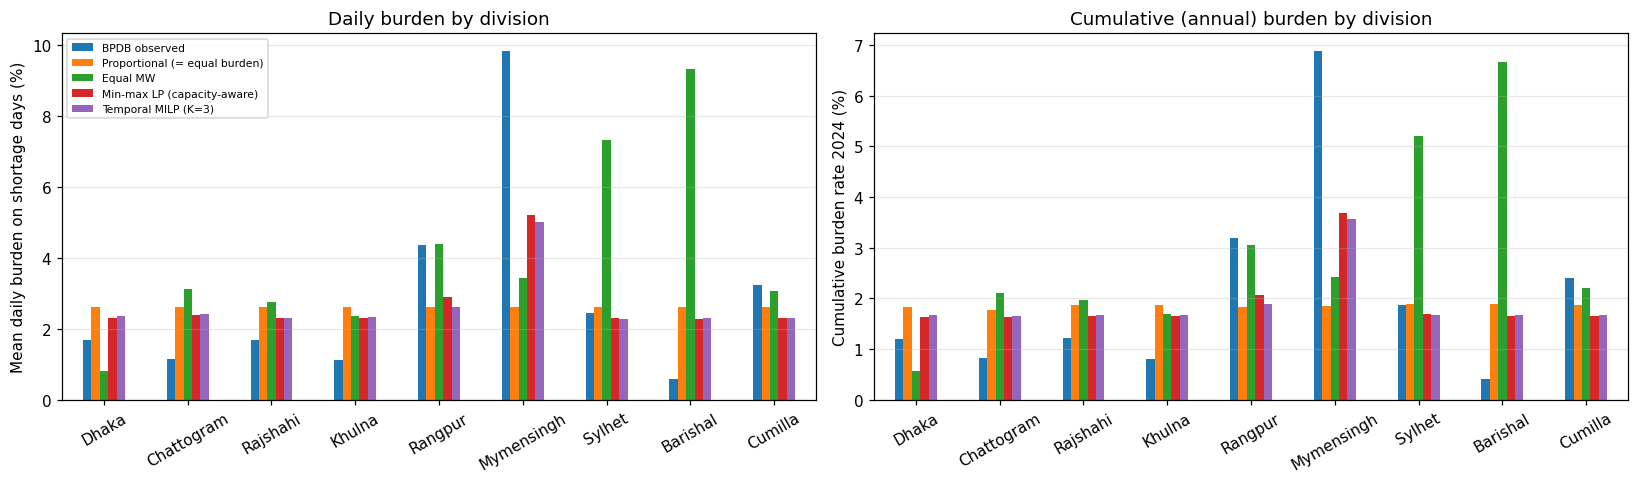

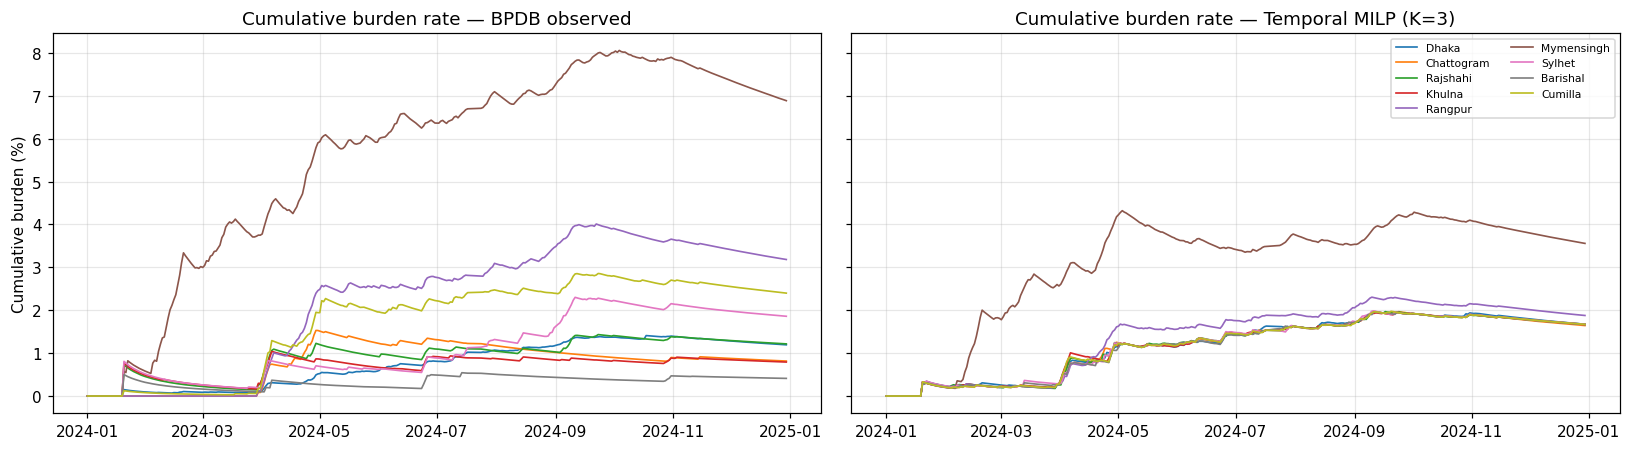

In [68]:
# Figure 11: burden by division under each allocation + final-year cumulative burden
last_year = max(CFG.alloc_years)
cum_last = pd.DataFrame({n: cumulative_burden(X, Dm, YRS)[last_year] for n, (X, _) in ALLOCS.items()}, index=DIVS)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
div_burden.plot(kind="bar", ax=axes[0], rot=30)
axes[0].set_ylabel("Mean daily burden on shortage days (%)"); axes[0].set_title("Daily burden by division")
axes[0].legend(fontsize=7); axes[0].grid(alpha=0.3, axis="y")
cum_last.plot(kind="bar", ax=axes[1], rot=30, legend=False)
axes[1].set_ylabel(f"Cumulative burden rate {last_year} (%)"); axes[1].set_title("Cumulative (annual) burden by division")
axes[1].grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.savefig(CFG.out_dir / "fig11_allocation_by_division.png", dpi=600)
plt.show()

# Figure 12: cumulative burden trajectories, BPDB observed vs temporal MILP (last year)
m_last = YRS == last_year
dates_last = A.loc[m_last, "Date"]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), sharey=True)
for ax, (name, X) in zip(axes, [("BPDB observed", X_obs), (f"Temporal MILP (K={CFG.MILP_MAX_CONSEC_DAYS})", X_milp)]):
    traj = 100 * np.cumsum(X[m_last], axis=0) / np.cumsum(Dm[m_last], axis=0)
    for j, d in enumerate(DIVS):
        ax.plot(dates_last, traj[:, j], label=d, lw=1.1)
    ax.set_title(f"Cumulative burden rate — {name}"); ax.grid(alpha=0.3)
axes[0].set_ylabel("Cumulative burden (%)"); axes[1].legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.savefig(CFG.out_dir / "fig12_cumulative_burden_trajectories.png", dpi=600)
plt.show()

###  Robustness: Shapley allocation

With the v2 characteristic function $v(S)=S_t\sum_{d\in S}D_d/\sum_d D_d$ the game is additive, so the Shapley value equals the proportional allocation and the "Shapley residual" is exactly *observed − proportional*. We verify this numerically; the Shapley layer therefore adds no information beyond benchmark 2 and is kept only as a robustness check.

In [69]:
def shapley_values(n, characteristic_fn):
    idx = list(range(n))
    weights = {s: math.factorial(s) * math.factorial(n - s - 1) / math.factorial(n) for s in range(n)}
    phi = np.zeros(n)
    for bits in range(1 << n):
        S = [i for i in idx if bits & (1 << i)]
        vS = characteristic_fn(S)
        for i in idx:
            if i in S: continue
            phi[i] += weights[len(S)] * (characteristic_fn(S + [i]) - vS)
    return phi

shap_days = np.where(SD)[0]
if CFG.MODE == "FAST":
    shap_days = np.random.default_rng(SEED).choice(shap_days, size=min(40, len(shap_days)), replace=False)
max_diff, resid = 0.0, []
for t in shap_days:
    d_row, s_t = Dm[t], S_req[t]
    phi = shapley_values(len(DIVS), lambda S: s_t * d_row[S].sum() / d_row.sum() if S else 0.0)
    max_diff = max(max_diff, np.abs(phi - X_prop[t]).max())
    resid.append(X_obs[t] - phi)
assert max_diff < 1e-6, "Shapley value differs from proportional allocation"
shapley_summary = pd.DataFrame({"Division": DIVS,
                                "Mean Shapley residual (MW)": np.mean(resid, axis=0).round(1),
                                "Mean observed − proportional (MW)": (X_obs - X_prop)[shap_days].mean(0).round(1)})
print(f"Max |Shapley − proportional| over {len(shap_days)} days: {max_diff:.2e} MW (identical)\n")
print(shapley_summary.to_string(index=False))

Max |Shapley − proportional| over 40 days: 1.59e-12 MW (identical)

  Division  Mean Shapley residual (MW)  Mean observed − proportional (MW)
     Dhaka                       -23.7                              -23.7
Chattogram                       -28.4                              -28.4
  Rajshahi                       -25.1                              -25.1
    Khulna                       -35.5                              -35.5
   Rangpur                        16.0                               16.0
Mymensingh                        96.9                               96.9
    Sylhet                         5.3                                5.3
  Barishal                       -10.2                              -10.2
   Cumilla                         4.6                                4.6


### Rotation–Equity Frontier

Rotation limits (fewer consecutive curtailment days per division) and cumulative burden equity pull in different directions under minimum-activation blocks. We re-solve the MILP for each $K$ in `FRONTIER_K` and place BPDB's observed allocation and the continuous benchmarks on the same axes. Proportional/LP allocations have no activation block, so they curtail every division every shortage day — they are equity references, not operationally equivalent schedules.

Frontier solved in 113.3s

                   Allocation  mean_longest_run_days  cum_burden_range  cum_burden_max  mean_daily_max_burden  divisions_curtailed_per_day  rotation_violation_days
                     MILP K=1                  7.778             2.198           3.733                  6.251                        4.224                    251.0
                     MILP K=2                  8.222             1.983           3.617                  5.963                        4.858                    192.0
                     MILP K=3                  8.222             1.916           3.559                  5.819                        5.192                    149.0
                     MILP K=5                  8.778             1.850           3.505                  5.693                        5.356                     84.0
                     MILP K=∞                 14.333             1.780           3.449                  5.572                        5.584               

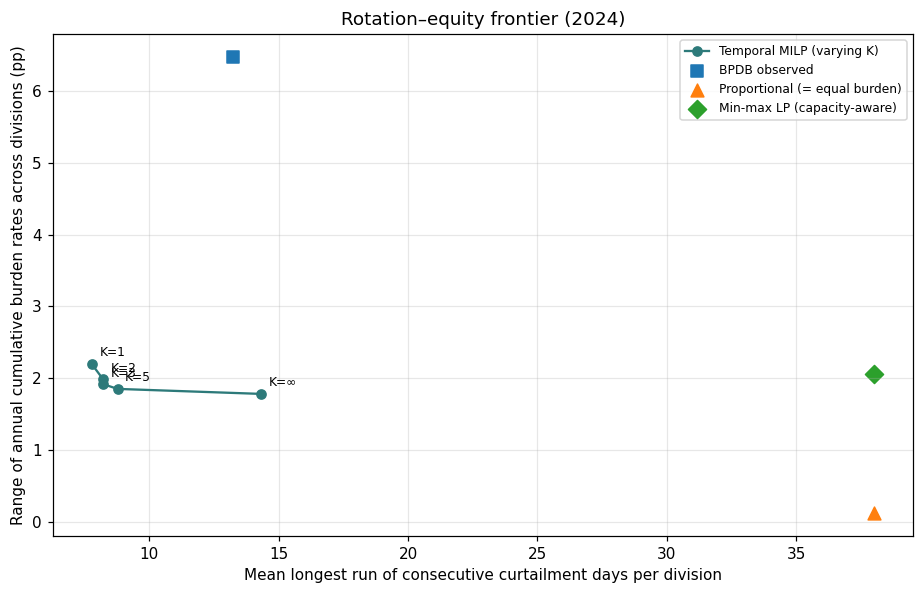

In [70]:
frontier_rows = []
t0 = time.time()
for K in CFG.FRONTIER_K:
    if K == CFG.MILP_MAX_CONSEC_DAYS:
        Xk, Yk, info = X_milp, Y_milp, milp_info
    else:
        Xk, Yk, info = run_temporal_milp(Dm, S_req, LB, YRS, K, CFG)
    m = allocation_metrics(f"MILP K={K if K is not None else '∞'}", Xk, Yk)
    m["rotation_violation_days"] = info["rotation_violation_days"]
    frontier_rows.append(m)
for n in ["BPDB observed", "Proportional (= equal burden)", "Min-max LP (capacity-aware)"]:
    X, Y = ALLOCS[n]
    m = allocation_metrics(n, X, Y); m["rotation_violation_days"] = np.nan
    frontier_rows.append(m)
frontier = pd.DataFrame(frontier_rows).round(3)
print(f"Frontier solved in {time.time()-t0:.1f}s\n")
print(frontier[["Allocation", "mean_longest_run_days", "cum_burden_range", "cum_burden_max",
                "mean_daily_max_burden", "divisions_curtailed_per_day", "rotation_violation_days"]].to_string(index=False))

# Figure 13
fig, ax = plt.subplots(figsize=(8.5, 5.5))
mil = frontier[frontier.Allocation.str.startswith("MILP")]
ax.plot(mil["mean_longest_run_days"], mil["cum_burden_range"], "o-", color="#2d7a7a", label="Temporal MILP (varying K)")
for _, rw in mil.iterrows():
    ax.annotate(rw["Allocation"].replace("MILP ", ""), (rw["mean_longest_run_days"], rw["cum_burden_range"]),
                textcoords="offset points", xytext=(5, 5), fontsize=8)
for n, mk in [("BPDB observed", "s"), ("Proportional (= equal burden)", "^"), ("Min-max LP (capacity-aware)", "D")]:
    rw = frontier[frontier.Allocation == n].iloc[0]
    ax.scatter(rw["mean_longest_run_days"], rw["cum_burden_range"], marker=mk, s=70, label=n)
ax.set_xlabel("Mean longest run of consecutive curtailment days per division")
ax.set_ylabel("Range of annual cumulative burden rates across divisions (pp)")
ax.set_title(f"Rotation–equity frontier ({', '.join(map(str, CFG.alloc_years))})")
ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(CFG.out_dir / "fig13_rotation_equity_frontier.png", dpi=600)
plt.show()

In [71]:
# Reconciliation panel (division-day) for downstream users
panel[["Date", "year", "regime", "cp_regime", "division", "demand", "supply", "reported", "gap", "burden"]] \
    .to_csv(CFG.out_dir / "reconciliation_panel.csv", index=False)
df[["Date", "year", "regime", "cp_regime"] + list(LAYERS) + ["system_burden", "nat_minus_div_gap"]] \
    .to_csv(CFG.out_dir / "daily_layers.csv", index=False)

# Tables
recon_by_year.to_csv(CFG.out_dir / "table_reconciliation_by_year.csv")
disc_table.to_csv(CFG.out_dir / "table_reporting_discrepancy.csv", index=False)
disc_ci.to_csv(CFG.out_dir / "table_discrepancy_bootstrap_ci.csv")
eta_ci.to_csv(CFG.out_dir / "table_conversion_ratio_ci.csv")
coef_table.to_csv(CFG.out_dir / "table_panel_regression_system.csv")
gas_sens.to_csv(CFG.out_dir / "table_division_gas_sensitivity.csv", index=False)
cv_table.to_csv(CFG.out_dir / "table_rolling_origin_validation.csv", index=False)
err_table.to_csv(CFG.out_dir / "table_error_by_division_stress.csv", index=False)
if not quarterly_table.empty:
    quarterly_table.to_csv(CFG.out_dir / "table_quarterly_origins.csv", index=False)
for task, t in shap_tables.items():
    t.to_csv(CFG.out_dir / f"table_shap_groups_{task}.csv")
vulnerability.to_csv(CFG.out_dir / "table_division_vulnerability.csv", index=False)
alloc_table.to_csv(CFG.out_dir / "table_allocation_comparison.csv", index=False)
div_burden.to_csv(CFG.out_dir / "table_allocation_burden_by_division.csv")
frontier.to_csv(CFG.out_dir / "table_rotation_equity_frontier.csv", index=False)
shapley_summary.to_csv(CFG.out_dir / "table_shapley_robustness.csv", index=False)
with open(CFG.out_dir / "panel_regression_summary.txt", "w") as f:
    f.write(panel_ols.summary().as_text())

# Allocations (long format)
alloc_long = pd.concat([
    pd.DataFrame(X, columns=DIVS).assign(Date=A["Date"].values, allocation=n)
      .melt(id_vars=["Date", "allocation"], var_name="division", value_name="curtailment_MW")
    for n, (X, _) in ALLOCS.items()])
alloc_long.to_csv(CFG.out_dir / "allocations_long.csv", index=False)

# ---- TL;DR summary ----
final_cv = cv_table[cv_table.origin == FINAL_ORIGIN]
best = lambda task: final_cv[final_cv.task == task].sort_values("MAE").iloc[0]
best_skill = lambda task: (final_cv[(final_cv.task == task) & (final_cv.model != "Persistence")]
                           .sort_values("MSE_skill_vs_persistence", ascending=False).iloc[0])
def fmt_model(r):
    return (f"{r['model']} (MAE {r['MAE']:.3f} pp, R2 {r['R2']:.3f}, "
            f"MSE skill vs persistence {r.get('MSE_skill_vs_persistence', 0):+.3f})")
top_shap = (100 * pd.DataFrame(np.abs(shap_store["diagnostic"][0]), columns=shap_store["diagnostic"][1].columns)
            .T.groupby([feature_group(c) for c in shap_store["diagnostic"][1].columns]).sum().T.mean()
            .pipe(lambda s: s / s.sum()).sort_values(ascending=False))
gc = gas_sens[gas_sens.regime == "crisis"].sort_values("beta_gas", ascending=False).iloc[0]
arow = alloc_table.set_index("Allocation")
summary = {
    "mode": CFG.MODE, "n_bootstrap": CFG.n_bootstrap, "seed": SEED,
    "rows": int(len(df)), "date_range": [str(df.Date.min().date()), str(df.Date.max().date())],
    "data_quality": DQ,
    "pct_division_days_consistent_Lrep_eq_D_minus_S": round(float(share_consistent), 2),
    "mean_MW_reported_shedding": round(float(df["total_reported_shedding"].mean()), 1),
    "mean_MW_divisional_gap": round(float(df["total_div_gap"].mean()), 1),
    "mean_MW_national_peak_gap": round(float(df["national_peak_gap"].mean()), 1),
    "mean_MW_gas_coal_hydro": round(float(df["upstream_constraints"].mean()), 1),
    "mean_MW_maintenance": round(float(df["maintenance"].mean()), 1),
    "conversion_eta_pct_by_regime": eta_ci.loc["eta_C"].loc["regime"]["estimate"].to_dict(),
    "change_points": [str(d.date()) for d in cp_dates],
    "ARI_calendar_vs_changepoint": round(float(ari), 3),
    "lowest_MAE_by_task_final_origin": {t: fmt_model(best(t)) for t in FEATURE_SETS},
    "highest_skill_by_task_final_origin": {t: fmt_model(best_skill(t)) for t in FEATURE_SETS},
    "hurdle_detection_AUC_final_origin": {t: round(float(final_cv[(final_cv.task == t) & (final_cv.model == "Hurdle")]["AUC"].iloc[0]), 3)
                                          for t in FEATURE_SETS},
    "top_shap_group_diagnostic": f"{top_shap.index[0]} ({top_shap.iloc[0]:.1f}%)",
    "most_gas_sensitive_division_crisis": f"{gc['Division']} ({gc['beta_gas']:.2f} pp per 1,000 MW)",
    "alloc_years": list(CFG.alloc_years),
    "mean_daily_max_burden_pct": arow["mean_daily_max_burden"].to_dict(),
    "cum_burden_range_pp": arow["cum_burden_range"].to_dict(),
    "milp_info": milp_info,
}
with open(CFG.out_dir / "run_summary.json", "w") as f:
    json.dump(summary, f, indent=2, default=str)

tldr = pd.DataFrame([
    ("Division-days where L_rep = D − S (within tolerance)", f"{share_consistent:.2f}%"),
    ("Mean reported shedding / divisional gap / national peak gap (MW/day)",
     f"{summary['mean_MW_reported_shedding']} / {summary['mean_MW_divisional_gap']} / {summary['mean_MW_national_peak_gap']}"),
    ("Mean gas+coal+hydro / maintenance (MW/day)", f"{summary['mean_MW_gas_coal_hydro']} / {summary['mean_MW_maintenance']}"),
    ("Constraint-to-shortfall conversion η by regime (%)",
     ", ".join(f"{k}: {v:.1f}" for k, v in summary["conversion_eta_pct_by_regime"].items())),
    ("Data-driven change points (ARI vs calendar)", f"{', '.join(summary['change_points'])} (ARI {ari:.2f})"),
    (f"Lowest MAE, nowcast, {FINAL_ORIGIN}", summary["lowest_MAE_by_task_final_origin"]["nowcast"]),
    (f"Highest skill vs persistence, nowcast, {FINAL_ORIGIN}", summary["highest_skill_by_task_final_origin"]["nowcast"]),
    (f"Highest skill vs persistence, early warning, {FINAL_ORIGIN}", summary["highest_skill_by_task_final_origin"]["early_warning"]),
    (f"Hurdle shortfall-detection AUC (nowcast / early warning)",
     f"{summary['hurdle_detection_AUC_final_origin']['nowcast']} / {summary['hurdle_detection_AUC_final_origin']['early_warning']}"),
    ("Top SHAP feature group (diagnostic)", summary["top_shap_group_diagnostic"]),
    ("Most gas-sensitive division (crisis)", summary["most_gas_sensitive_division_crisis"]),
    ("Mean daily max burden: BPDB → min-max LP (%)",
     f"{arow.loc['BPDB observed','mean_daily_max_burden']:.2f} → {arow.loc['Min-max LP (capacity-aware)','mean_daily_max_burden']:.2f}"),
    ("Cumulative burden range: BPDB → temporal MILP (pp)",
     f"{arow.loc['BPDB observed','cum_burden_range']:.2f} → {arow.iloc[-1]['cum_burden_range']:.2f}"),
], columns=["Metric", "Value"])
print("TL;DR\n"); print(tldr.to_string(index=False))
print("\nArtifacts written to", CFG.out_dir)
for p in sorted(CFG.out_dir.glob("*")):
    print("  ", p.name)

TL;DR

                                                              Metric                                                                 Value
                Division-days where L_rep = D − S (within tolerance)                                                                99.60%
Mean reported shedding / divisional gap / national peak gap (MW/day)                                                 127.0 / 127.5 / 125.1
                          Mean gas+coal+hydro / maintenance (MW/day)                                                       2633.4 / 2189.5
                  Constraint-to-shortfall conversion η by regime (%)                                covid: 0.0, crisis: 7.3, recovery: 6.6
                         Data-driven change points (ARI vs calendar)                         2020-05-01, 2021-09-01, 2024-09-01 (ARI 0.42)
                                           Lowest MAE, nowcast, 2024 LightGBM-L1 (MAE 1.196 pp, R2 0.533, MSE skill vs persistence +0.285)
                    

---
## Interpretation guide & scope

1. **Reconciliation.** If the reported column equals $D-S$ almost everywhere (Section 3), layers A and B are one measurement; the research question is the divergence between divisional imbalance, national peak shortfall and upstream constraints — not "hidden" shedding.
2. **Conversion.** Compare η across regimes and the P(shortfall | constraint quintile) curves: the same constraint level producing different shortfall probabilities is the core evidence that constraints are not unmet load.
3. **Models.** Judge models by skill vs persistence, shortfall-day MAE and detection AUC on the 2023/2024 origins and the quarterly check; the ≤2021→2022 fold is a regime-transfer test that every learner is expected to fail. Report the panel coefficients (Section 7) for effect sizes and the SHAP groups (Section 9) as associations, not causal effects.
4. **Allocation.** The LP/MILP results are counterfactual benchmarks under stated assumptions (capacity proxy, activation block, rotation limit). Sensitivity: vary `CAPACITY_WINDOW_DAYS`, `MILP_MIN_ACTIVE_FRAC`, `MILP_MAX_CONSEC_DAYS` and the weights in `Config`.
5. **FULL mode.** Set `CFG.MODE = "FULL"` for 2,000 bootstrap draws and the 2022–2024 allocation study.



## Tuning & Sensitivity

**Rule:** hyperparameters are chosen on the inner validation year only (train ≤2022, validate 2023), and the test year (2024) is scored **once** with the chosen settings. Allocation assumptions are *not* tuned — their sensitivity is reported instead, because picking the value that makes the observed allocation look worst would be cherry-picking. Set `Config.RUN_SECTION_13 = False` to skip this section.

In [72]:
# Cell 13.1 — hyperparameter tuning for the forecasting tasks (nowcast, early_warning)
import itertools, dataclasses
TUNE_TRAIN_END, TUNE_VAL, TEST_YEAR = 2022, 2023, 2024
tune_table, best_params = pd.DataFrame(), {}
if CFG.RUN_SECTION_13:
    def eval_params(model_name, task, params, tr, te):
        fs = FEATURE_SETS[task]
        if model_name == "PanelRidge":
            cols = fs["num"] + fs["inter"]
            pipe = make_ridge(cols); pipe.set_params(ridge__alpha=params["alpha"])
            pipe.fit(tr[cols + ["division"]], tr["burden"]); p = pipe.predict(te[cols + ["division"]]); s = p
        elif model_name == "LightGBM":
            cols = fs["num"] + ["div_code"]
            m, _ = lgbm_fit(tr, cols, "burden", objective="regression", params=params)
            p = m.predict(te[cols]); s = p
        return evaluate_fold(te, np.clip(p, 0, 100), s)

    GRIDS = {
        "PanelRidge": [dict(alpha=a) for a in (0.1, 1, 10, 100, 1000)],
        "LightGBM": [dict(num_leaves=nl, min_data_in_leaf=mdl, learning_rate=lr)
                     for nl, mdl, lr in itertools.product((7, 15, 31), (50, 100, 200), (0.02, 0.05))],
    }
    tr_in = panel[panel.year <= TUNE_TRAIN_END]; va_in = panel[panel.year == TUNE_VAL]
    tr_out = panel[panel.year < TEST_YEAR];      te_out = panel[panel.year == TEST_YEAR]
    rows = []
    t0 = time.time()
    for task in ("nowcast", "early_warning"):
        for mname, grid in GRIDS.items():
            scores = [(p, eval_params(mname, task, p, tr_in, va_in)) for p in grid]
            rows += [dict(task=task, model=mname, params=str(p), **s) for p, s in scores]
            best_p = min(scores, key=lambda x: x[1]["MAE"])[0]          # selection on validation MAE
            best_params[(task, mname)] = best_p
            test = eval_params(mname, task, best_p, tr_out, te_out)       # single look at the test year
            print(f"{task:13s} {mname:10s} best={best_p}\n{'':25s}test {TEST_YEAR}: MAE={test['MAE']:.3f} "
                  f"R2={test['R2']:.3f} skill vs persistence={test['MSE_skill_vs_persistence']:+.3f}")
    tune_table = pd.DataFrame(rows).round(4)
    tune_table.to_csv(CFG.out_dir / "table_tuning_inner_validation.csv", index=False)
    print(f"\nTuning finished in {time.time()-t0:.1f}s. To adopt the tuned values, copy them into "
          "Config.LGBM_PARAMS / Config.RIDGE_ALPHA and re-run the notebook.")

nowcast       PanelRidge best={'alpha': 0.1}
                         test 2024: MAE=1.620 R2=0.521 skill vs persistence=+0.267
nowcast       LightGBM   best={'num_leaves': 7, 'min_data_in_leaf': 50, 'learning_rate': 0.05}
                         test 2024: MAE=1.543 R2=0.567 skill vs persistence=+0.336
early_warning PanelRidge best={'alpha': 100}
                         test 2024: MAE=1.612 R2=0.475 skill vs persistence=+0.196
early_warning LightGBM   best={'num_leaves': 7, 'min_data_in_leaf': 50, 'learning_rate': 0.05}
                         test 2024: MAE=1.577 R2=0.482 skill vs persistence=+0.207

Tuning finished in 13.7s. To adopt the tuned values, copy them into Config.LGBM_PARAMS / Config.RIDGE_ALPHA and re-run the notebook.


In [73]:
# Cell 13.2 — sensitivity of the allocation (OR) layer to its assumptions
sens_table = pd.DataFrame()
if CFG.RUN_SECTION_13:
    def capacity_lb(window_days):
        cap = np.column_stack([df.set_index("Date")[f"{d}_supply"].reindex(FULL_RANGE)
                               .rolling(window_days, min_periods=1).max().reindex(df["Date"]).values
                               for d in DIVS])[df["year"].isin(CFG.alloc_years).values]
        return np.clip(Dm - cap, 0, None)

    sens_rows = []
    LB_base = LB.copy()
    for W, kappa in itertools.product((14, 30, 60), (0.005, 0.01, 0.02)):
        K = CFG.MILP_MAX_CONSEC_DAYS
        cfg_s = dataclasses.replace(CFG, CAPACITY_WINDOW_DAYS=W, MILP_MIN_ACTIVE_FRAC=kappa)
        LB = capacity_lb(W)                                   # allocation_metrics reads the global LB
        X_lp_s = np.zeros_like(Dm)
        for t in np.where(SD)[0]:
            X_lp_s[t], _ = solve_minmax_lp(S_req[t], Dm[t], LB[t])
        X_m, Y_m, info = run_temporal_milp(Dm, S_req, LB, YRS, K, cfg_s)
        for name, X, Y in [("Min-max LP", X_lp_s, None), (f"MILP K={K}", X_m, Y_m)]:
            m = allocation_metrics(name, X, Y)
            sens_rows.append(dict(W=W, kappa=kappa, K=K,
                                  rotation_viol=info["rotation_violation_days"] if name.startswith("MILP") else np.nan, **m))
    LB = LB_base                                              # restore the base case
    sens_table = pd.DataFrame(sens_rows).round(3)
    print(sens_table[["W", "kappa", "Allocation", "mean_daily_max_burden", "cum_burden_range",
                      "mean_longest_run_days", "divisions_curtailed_per_day", "rotation_viol"]].to_string(index=False))
    sens_table.to_csv(CFG.out_dir / "table_allocation_sensitivity.csv", index=False)

 W  kappa Allocation  mean_daily_max_burden  cum_burden_range  mean_longest_run_days  divisions_curtailed_per_day  rotation_viol
14  0.005 Min-max LP                  6.112             2.590                 38.000                        8.530            NaN
14  0.005   MILP K=3                  6.261             2.490                  9.444                        5.393          195.0
14  0.010 Min-max LP                  6.112             2.590                 38.000                        8.530            NaN
14  0.010   MILP K=3                  6.331             2.471                  9.111                        4.977          188.0
14  0.020 Min-max LP                  6.112             2.590                 38.000                        8.530            NaN
14  0.020   MILP K=3                  6.535             2.469                  9.000                        4.457          187.0
30  0.005 Min-max LP                  5.453             2.063                 38.000             

In [74]:
# Cell 13.3 — sensitivity of bootstrap intervals to block length
blk_table = pd.DataFrame()
if CFG.RUN_SECTION_13:
    blk_rows = []
    for L in (7, 14, 28):
        ci = block_bootstrap(df[conv_cols], eta_stat, dataclasses.replace(CFG, BLOCK_LEN_DAYS=L))
        sub = ci.loc[[k for k in ci.index if k[0] == "eta_C" and k[1] == "regime"]]
        for (_, _, lvl), r in sub.iterrows():
            blk_rows.append(dict(block_len=L, regime=lvl, **r.round(2).to_dict()))
    blk_table = pd.DataFrame(blk_rows)
    print(blk_table.pivot(index="regime", columns="block_len", values=["estimate", "ci_low", "ci_high"]).to_string())
    blk_table.to_csv(CFG.out_dir / "table_block_length_sensitivity.csv", index=False)

          estimate             ci_low             ci_high              
block_len       7     14    28     7     14    28      7      14     28
regime                                                                 
covid         0.03  0.03  0.03   0.00  0.00  0.00    0.07   0.07   0.06
crisis        7.29  7.29  7.29   5.33  4.53  3.50    9.55  10.33  11.65
recovery      6.60  6.60  6.60   4.64  4.27  3.85    9.03  10.00  10.37


In [75]:
# Zip all outputs for download (Kaggle Output tab or local fallback folder)
import zipfile
output_folder = str(CFG.out_dir)
zip_filename = os.path.join(output_folder, "output.zip")
with zipfile.ZipFile(zip_filename, "w", zipfile.ZIP_DEFLATED) as zipf:
    for root, dirs, files in os.walk(output_folder):
        for file in files:
            file_path = os.path.join(root, file)
            if file_path == zip_filename:
                continue
            zipf.write(file_path, os.path.relpath(file_path, output_folder))
print(f"Zip created: {zip_filename}  ({os.path.getsize(zip_filename) / (1024*1024):.2f} MB)")

Zip created: /kaggle/working/output.zip  (11.70 MB)
